# Difusión Global y Estimación Espacial del COVID-19 en Europa
## Segunda Práctica Calificada · Estadística Espacial · Grupo 6

**Universidad Nacional Mayor de San Marcos** · Escuela Profesional de Estadística

| Integrantes | Participación |
|---|---|
| Briceño Ypanaque, Gabriel | 100 % |
| Espinoza Luna, Wilder | 100 % |
| Isase Camara, Vicente | 100 % |
| Montoya Juro, Oscar | 100 % |
| Pablo Machaca, Gerson | 100 % |
| Polastre Mamani, Frank | 100 % |

**Docente:** Misael Erikson Maguiña Palma

---

### Contexto
El dataset *Data Spatial* contiene la serie diaria acumulada de casos de COVID-19 (Confirmed, Deaths, Recovered, Active) reportados por país o provincia entre el 22/01/2020 y el 27/07/2020 (el enunciado delimita el periodo de estudio hasta el 26/07/2020). Cada registro está georreferenciado por un punto (centroide del país o provincia) en coordenadas geográficas WGS84. En este cuaderno los puntos se tratan como observaciones de un fenómeno espacial continuo para describir su patrón, construir superficies de propagación (IDW, Kriging Ordinario y Cokriging Ordinario) y cuantificar su incertidumbre.

### Objetivo general
Modelar la distribución espacial de los casos confirmados y fallecidos por COVID-19 en Europa al 26/07/2020 mediante métodos geoestadísticos, para obtener superficies continuas de propagación y mapas de incertidumbre que orienten la asignación de recursos sanitarios.

### Objetivos específicos
1. Preparar y proyectar los datos (WGS84 → ETRS89-LAEA, EPSG:3035) y justificar el corte temporal y la transformación $\ln(x+1)$.
2. Caracterizar el patrón puntual (KDE, funciones $G$ y $K$ de Ripley con envolventes de CSR) e interpolar con IDW evaluando el parámetro de potencia $p$.
3. Ajustar semivariogramas (esférico, exponencial, gaussiano), estimar por Kriging Ordinario y Cokriging Ordinario (Confirmed primaria, Deaths secundaria) y seleccionar el mejor estimador por validación cruzada (RMSE, RMSS).
4. Traducir las superficies y mapas de varianza en recomendaciones territoriales cuantificadas.

### Fuentes de datos
| Fuente | Uso |
|---|---|
| *Data Spatial* (Johns Hopkins CSSE, compilado; leído desde [GitHub](https://github.com/wilder1111/BI1/blob/main/Data%20Spatial.csv)) | Variables epidemiológicas y coordenadas |
| Our World in Data (OWID) | Población, densidad, camas hospitalarias por 1000 hab., % de población ≥ 65 años |
| Natural Earth 1:50m | Fronteras de países, máscara de interpolación y ventana de estudio |

## 0. Configuración del entorno

In [1]:
# Librerías (ejecutar una vez si faltan):
# %pip install geopandas pykrige libpysal esda pyproj shapely statsmodels
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from shapely.geometry import box
from shapely import contains_xy
from scipy import stats
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist, squareform, cdist
from scipy.optimize import least_squares, minimize
import statsmodels.api as sm
from pyproj import Geod
from pykrige.ok import OrdinaryKriging
from libpysal.weights import KNN
from esda.moran import Moran

# Rutas del proyecto
BASE = Path.cwd()
DATA, FIG, RES = BASE / "data", BASE / "figuras", BASE / "resultados"
for p in (DATA, FIG, RES):
    p.mkdir(exist_ok=True)

# Parámetros globales del análisis
SEED = 2020
rng = np.random.default_rng(SEED)
np.random.seed(SEED)                 # reproducibilidad de las permutaciones de esda
FECHA_CORTE = "2020-07-26"          # último día del periodo de estudio del enunciado
CRS_GEO, CRS_PROJ = "EPSG:4326", "EPSG:3035"
BBOX = (-25.0, 34.0, 46.0, 72.0)    # Europa continental + islas atlánticas (lon_min, lat_min, lon_max, lat_max)
CELDA_KM = 25                        # resolución de la grilla de predicción

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "font.size": 9})

def guardar_fig(fig, nombre):
    """Guarda la figura en PNG (para el informe LaTeX y la web)."""
    fig.savefig(FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")

### 0.1 Carga de datos e integración con fuentes externas
Las fuentes externas se descargan una sola vez y se guardan recortadas (Europa, fecha de corte) para que el proyecto sea liviano y reproducible.

In [2]:
URL_OWID = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"
URL_NE = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson"
EXTRA_ASIA = ["Turkey", "Cyprus", "Georgia", "Armenia"]   # países de la Región Europa OMS fuera del continente europeo NE

ruta_owid = DATA / "owid_europa_2020-07-26.csv"
if not ruta_owid.exists():
    cols = ["iso_code", "continent", "location", "date", "population", "population_density",
            "median_age", "aged_65_older", "gdp_per_capita", "hospital_beds_per_thousand"]
    owid_full = pd.read_csv(URL_OWID, usecols=cols)
    owid_full = owid_full[(owid_full["date"] == FECHA_CORTE) &
                          ((owid_full["continent"] == "Europe") | owid_full["location"].isin(EXTRA_ASIA))]
    owid_full.drop(columns="date").to_csv(ruta_owid, index=False)

ruta_ne = DATA / "ne_europa_50m.geojson"
if not ruta_ne.exists():
    ne = gpd.read_file(URL_NE)
    ne = ne[(ne["CONTINENT"] == "Europe") | ne["ADMIN"].isin(EXTRA_ASIA)][["ADMIN", "ADM0_A3", "CONTINENT", "geometry"]]
    ne = gpd.clip(ne, box(*BBOX))
    ne.to_file(ruta_ne, driver="GeoJSON")

# Fuente principal: repositorio GitHub (lectura automatizada); respaldo local si no hay conexión
URL_DATA = "https://raw.githubusercontent.com/wilder1111/BI1/main/Data%20Spatial.csv"
try:
    raw = pd.read_csv(URL_DATA, parse_dates=["Date"])
    print("Data Spatial leído desde GitHub:", URL_DATA)
except Exception as err:
    raw = pd.read_csv(DATA / "Data Spatial.csv", parse_dates=["Date"])
    print(f"Sin acceso a GitHub ({type(err).__name__}); se usa la copia local data/Data Spatial.csv")
owid = pd.read_csv(ruta_owid)
paises = gpd.read_file(ruta_ne)

print(f"Data Spatial: {raw.shape[0]:,} filas, {raw['Date'].nunique()} fechas, "
      f"{raw.groupby(['Province/State', 'Country/Region'], dropna=False).ngroups} ubicaciones")
print(f"OWID (recorte): {owid.shape}; Natural Earth (recorte): {paises.shape[0]} polígonos")
raw.head()

Data Spatial leído desde GitHub: https://raw.githubusercontent.com/wilder1111/BI1/main/Data%20Spatial.csv
Data Spatial: 49,068 filas, 188 fechas, 261 ubicaciones
OWID (recorte): (58, 9); Natural Earth (recorte): 54 polígonos


,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


### 0.2 Auditoría de calidad y limpieza de datos
Antes del análisis espacial se verifican la completitud, la unicidad, el dominio de los valores, la consistencia interna de las variables y la monotonía de las series acumuladas. También se cuantifica la magnitud del problema en la fecha de corte.

In [3]:
num = ["Confirmed", "Deaths", "Recovered", "Active"]
clave = ["Province/State", "Country/Region", "Date"]
grp = raw.sort_values("Date").groupby(["Province/State", "Country/Region"], dropna=False)
auditoria = pd.DataFrame([
    ("Registros totales", len(raw), "Informativo"),
    ("Valores faltantes en variables numéricas y coordenadas", int(raw[num + ["Lat", "Long"]].isna().sum().sum()), "Sin acción"),
    ("Province/State vacío (registro a nivel de país)", int(raw["Province/State"].isna().sum()), "Se usa Country/Region como identificador"),
    ("Filas duplicadas", int(raw.duplicated().sum()), "Sin acción"),
    ("Claves duplicadas (ubicación y fecha)", int(raw.duplicated(clave).sum()), "Sin acción"),
    ("Valores negativos en Confirmed, Deaths o Recovered", int((raw[num[:3]] < 0).sum().sum()), "Sin acción"),
    ("Valores negativos en Active", int((raw["Active"] < 0).sum()), "Variable excluida del análisis"),
    ("Inconsistencias Active ≠ Confirmed − Deaths − Recovered", int((raw["Active"] != raw["Confirmed"] - raw["Deaths"] - raw["Recovered"]).sum()), "Sin acción"),
    ("Disminuciones en la serie acumulada de Confirmed", int((grp["Confirmed"].diff() < 0).sum()), "Corrección retroactiva; el corte transversal no se ve afectado"),
    ("Disminuciones en la serie acumulada de Deaths", int((grp["Deaths"].diff() < 0).sum()), "Corrección retroactiva; el corte transversal no se ve afectado"),
    ("Coordenadas nulas o fuera de rango", int((((raw["Lat"] == 0) & (raw["Long"] == 0)) | (raw["Lat"].abs() > 90) | (raw["Long"].abs() > 180)).sum()), "Sin acción"),
    ("Ubicaciones con serie temporal incompleta", int((grp.size() != raw["Date"].nunique()).sum()), "Sin acción"),
], columns=["Control", "Resultado", "Tratamiento"])
display(auditoria)
auditoria.to_csv(RES / "f0_auditoria_calidad.csv", index=False)
print(f"Periodo del dataset: {raw['Date'].min():%d/%m/%Y} a {raw['Date'].max():%d/%m/%Y} ({raw['Date'].nunique()} fechas); "
      f"periodo de estudio del enunciado: 22/01/2020 a {pd.Timestamp(FECHA_CORTE):%d/%m/%Y}")

# Magnitud del problema en la fecha de corte
c0 = raw[raw["Date"] == FECHA_CORTE]
eur = c0[c0["WHO Region"] == "Europe"]
impacto = pd.DataFrame({
    "Ámbito": ["Mundo", "Región Europa OMS", "Participación de Europa (%)"],
    "Confirmed": [c0["Confirmed"].sum(), eur["Confirmed"].sum(), 100 * eur["Confirmed"].sum() / c0["Confirmed"].sum()],
    "Deaths": [c0["Deaths"].sum(), eur["Deaths"].sum(), 100 * eur["Deaths"].sum() / c0["Deaths"].sum()]}).round(1)
display(impacto)
impacto.to_csv(RES / "f0_impacto.csv", index=False)

,Control,Resultado,Tratamiento
0,Registros totales,49068,Informativo
1,Valores faltantes en variables numéricas y coo...,0,Sin acción
2,Province/State vacío (registro a nivel de país),34404,Se usa Country/Region como identificador
3,Filas duplicadas,0,Sin acción
4,Claves duplicadas (ubicación y fecha),0,Sin acción
5,"Valores negativos en Confirmed, Deaths o Recov...",0,Sin acción
6,Valores negativos en Active,18,Variable excluida del análisis
7,Inconsistencias Active ≠ Confirmed − Deaths − ...,0,Sin acción
8,Disminuciones en la serie acumulada de Confirmed,76,Corrección retroactiva; el corte transversal n...
9,Disminuciones en la serie acumulada de Deaths,53,Corrección retroactiva; el corte transversal n...


Periodo del dataset: 22/01/2020 a 27/07/2020 (188 fechas); periodo de estudio del enunciado: 22/01/2020 a 26/07/2020


,Ámbito,Confirmed,Deaths
0,Mundo,16251796.0,648621.0
1,Región Europa OMS,3277229.0,210840.0
2,Participación de Europa (%),20.2,32.5


---
# Fase 1. Preparación, Tratamiento Espacial y Geoprocesamiento

## 1.1 Georreferenciación y proyección espacial

### a) Sesgo de las distancias euclidianas sobre grados decimales
Las coordenadas $(\lambda,\varphi)$ en WGS84 son **ángulos** sobre un elipsoide, no posiciones en un plano. La distancia euclidiana en grados

$$d_{\deg}(s_i,s_j)=\sqrt{(\lambda_i-\lambda_j)^2+(\varphi_i-\varphi_j)^2}$$

no es una métrica física porque:

1. **Convergencia de meridianos (anisotropía artificial).** Un grado de latitud mide ≈ 111,3 km en todo el globo, pero un grado de longitud mide $111{,}3\cos\varphi$ km: ≈ 90 km a 36°N (Malta) y ≈ 38 km a 70°N (Noruega). Dos pares de puntos con el mismo $\Delta^\circ$ pueden estar a distancias reales muy distintas, y la métrica en grados trata como iguales separaciones que no lo son.
2. **Deformación de las clases de distancia del semivariograma.** El estimador de Matheron agrupa pares por $h$. Si $h$ está en grados, pares realmente lejanos en el norte se mezclan con pares cercanos en el sur dentro del mismo *lag*, lo que infla o reduce $\hat\gamma(h)$ de forma sistemática según la latitud.
3. **Parámetros sin significado físico.** El alcance $a$ y la pendiente del semivariograma quedarían en "grados", una unidad que no es constante en el espacio, y la condición de **estacionariedad intrínseca** (dependencia solo de $h$) se viola por construcción: la misma $\Delta^\circ$ representa distancias diferentes en distintas latitudes.
4. **Validez del modelo.** Las funciones de covarianza esférica, exponencial o gaussiana son definidas positivas en $\mathbb{R}^2$ con la distancia euclidiana real. Aplicadas sobre una métrica distorsionada, el sistema de Kriging puede perder condicionamiento y las varianzas de predicción quedan mal calibradas.

La celda siguiente cuantifica este sesgo comparando, para todos los pares de puntos europeos, la distancia en grados (×111,32 km) con la distancia geodésica sobre el elipsoide.

In [4]:
# Selección espacial: Región Europa OMS dentro de la ventana continental (excluye territorios de ultramar)
corte = raw[raw["Date"] == FECHA_CORTE].copy()
eu = corte[(corte["WHO Region"] == "Europe") &
           corte["Long"].between(BBOX[0], BBOX[2]) & corte["Lat"].between(BBOX[1], BBOX[3])].copy()
eu["Ubicacion"] = eu["Province/State"].fillna(eu["Country/Region"])
eu = eu.reset_index(drop=True)
excluidos = corte[(corte["WHO Region"] == "Europe") & ~corte.index.isin(
    corte[(corte["WHO Region"] == "Europe") & corte["Long"].between(BBOX[0], BBOX[2]) &
          corte["Lat"].between(BBOX[1], BBOX[3])].index)]
print(f"Puntos Región Europa OMS: {(corte['WHO Region'] == 'Europe').sum()} | dentro de la ventana: {len(eu)}")
print("Excluidos (ultramar o fuera de la zona de validez de EPSG:3035):")
print(", ".join(excluidos["Province/State"].fillna(excluidos["Country/Region"])))

# Distancia en grados vs geodésica (elipsoide WGS84)
geod = Geod(ellps="WGS84")
i, j = np.triu_indices(len(eu), 1)
lon, lat = eu["Long"].values, eu["Lat"].values
d_grados_km = np.hypot(lon[i] - lon[j], lat[i] - lat[j]) * 111.32
_, _, d_geo_m = geod.inv(lon[i], lat[i], lon[j], lat[j])
d_geo_km = d_geo_m / 1000
err_rel_grados = (d_grados_km - d_geo_km) / d_geo_km * 100

tabla_lon = pd.DataFrame({"Latitud": [36, 45, 55, 64, 70]})
tabla_lon["km por 1° de longitud"] = (111.32 * np.cos(np.radians(tabla_lon["Latitud"]))).round(1)
tabla_lon["km por 1° de latitud"] = 111.3
display(tabla_lon)
print(f"Error relativo de la distancia en grados: mediana {np.median(err_rel_grados):.1f} %, "
      f"P95 {np.percentile(np.abs(err_rel_grados), 95):.1f} %, máximo {np.abs(err_rel_grados).max():.1f} %")

Puntos Región Europa OMS: 80 | dentro de la ventana: 52
Excluidos (ultramar o fuera de la zona de validez de EPSG:3035):
Azerbaijan, Greenland, French Guiana, French Polynesia, Guadeloupe, Mayotte, New Caledonia, Reunion, Saint Barthelemy, St Martin, Martinique, Israel, Kazakhstan, Kyrgyzstan, Aruba, Curacao, Sint Maarten, Russia, Bermuda, Cayman Islands, Montserrat, Uzbekistan, Anguilla, British Virgin Islands, Turks and Caicos Islands, Falkland Islands (Malvinas), Saint Pierre and Miquelon, Tajikistan


,Latitud,km por 1° de longitud,km por 1° de latitud
0,36,90.1,111.3
1,45,78.7,111.3
2,55,63.9,111.3
3,64,48.8,111.3
4,70,38.1,111.3


Error relativo de la distancia en grados: mediana 29.9 %, P95 61.3 %, máximo 125.9 %


### b) Propuesta de Sistema de Coordenadas Proyectadas: ETRS89-LAEA (**EPSG:3035**)
Para Europa se propone **ETRS89 / LAEA Europe (EPSG:3035)**, proyección Azimutal Equivalente de Lambert centrada en 52°N, 10°E, sobre el datum ETRS89, con unidades en metros.

* Es el **estándar oficial de la Unión Europea** (directiva INSPIRE) para análisis estadístico paneuropeo y la base de la grilla estadística europea (EEA, Eurostat).
* Es **equivalente** (conserva áreas), lo que la hace adecuada para intensidades de procesos puntuales (KDE, $K$ de Ripley), y al ser **azimutal centrada** en el continente mantiene la distorsión de distancias baja (del orden de pocas unidades porcentuales) en toda Europa, frente a decenas de puntos porcentuales en grados.
* Alternativas descartadas: UTM (zonas de 6°, Europa ocupa más de 10 husos, sin plano común); Web Mercator EPSG:3857 (factor de escala $1/\cos\varphi$, más del 100 % de exageración en Escandinavia).
* Para el **Pacífico Occidental** el análogo sería una azimutal equidistante o Lambert cónica centrada en la región; no existe un EPSG equivalente oficial y se definiría una proyección personalizada (`+proj=aeqd +lat_0=... +lon_0=...`).

La celda siguiente proyecta los puntos y verifica la conservación de distancias frente a la geodésica.

,Métrica,Error relativo mediano (%),|Error| P95 (%),|Error| máximo (%)
0,"Euclidiana en grados (×111,32)",29.87,61.28,125.92
1,Euclidiana en EPSG:3035,-0.07,0.72,2.06


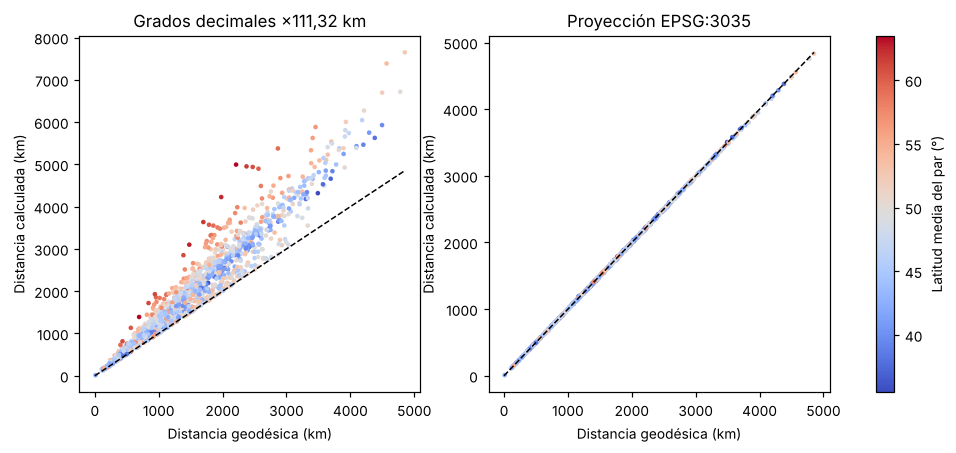

In [5]:
gdf = gpd.GeoDataFrame(eu, geometry=gpd.points_from_xy(eu["Long"], eu["Lat"]), crs=CRS_GEO).to_crs(CRS_PROJ)
xy = np.column_stack([gdf.geometry.x, gdf.geometry.y]) / 1000     # coordenadas en km
paises_p = paises.to_crs(CRS_PROJ)
paises_km = paises_p.copy()
paises_km["geometry"] = paises_p.geometry.scale(1 / 1000, 1 / 1000, origin=(0, 0))
region_km = paises_km.union_all()

d_proj_km = pdist(xy)
err_rel_proj = (d_proj_km - d_geo_km) / d_geo_km * 100
resumen_dist = pd.DataFrame({
    "Métrica": ["Euclidiana en grados (×111,32)", "Euclidiana en EPSG:3035"],
    "Error relativo mediano (%)": [np.median(err_rel_grados), np.median(err_rel_proj)],
    "|Error| P95 (%)": [np.percentile(np.abs(err_rel_grados), 95), np.percentile(np.abs(err_rel_proj), 95)],
    "|Error| máximo (%)": [np.abs(err_rel_grados).max(), np.abs(err_rel_proj).max()],
}).round(2)
display(resumen_dist)
resumen_dist.to_csv(RES / "f1_error_distancias.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
lat_media = (lat[i] + lat[j]) / 2
for ax, d, t in zip(axes, [d_grados_km, d_proj_km], ["Grados decimales ×111,32 km", "Proyección EPSG:3035"]):
    sc = ax.scatter(d_geo_km, d, c=lat_media, s=4, cmap="coolwarm")
    ax.plot([0, d_geo_km.max()], [0, d_geo_km.max()], "k--", lw=1)
    ax.set(xlabel="Distancia geodésica (km)", ylabel="Distancia calculada (km)", title=t)
fig.colorbar(sc, ax=axes, label="Latitud media del par (°)")
guardar_fig(fig, "f1_distancias_grados_vs_proyectadas")
plt.show()

**Análisis de resultados.** En grados, las distancias se sobrestiman sistemáticamente y el sesgo crece con la latitud (puntos rojos por encima de la diagonal): en el norte de Europa un grado de longitud mide menos de la mitad que en el Mediterráneo. En EPSG:3035 los pares se alinean con la diagonal y el error queda acotado a pocas unidades porcentuales. Todo el análisis posterior usa coordenadas proyectadas en kilómetros.

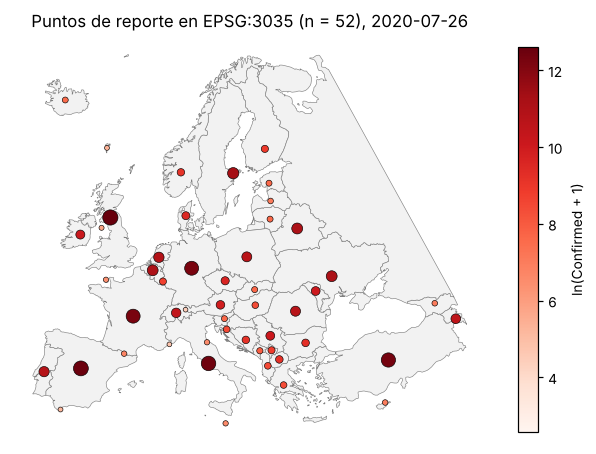

In [6]:
fig, ax = plt.subplots(figsize=(7, 6.5))
paises_km.plot(ax=ax, color="#f2f2f2", edgecolor="grey", lw=0.4)
s = ax.scatter(xy[:, 0], xy[:, 1], c=np.log1p(eu["Confirmed"]), s=np.sqrt(eu["Confirmed"]) / 6 + 8,
               cmap="Reds", edgecolor="k", lw=0.4)
fig.colorbar(s, ax=ax, shrink=0.7, label="ln(Confirmed + 1)")
ax.set_title(f"Puntos de reporte en EPSG:3035 (n = {len(eu)}), {FECHA_CORTE}")
ax.set_axis_off()
guardar_fig(fig, "f1_mapa_puntos")
plt.show()

## 1.2 Filtrado temporal y exploración geoestadística

### a) Necesidad de un corte temporal
Cada ubicación aparece una vez por día (188 fechas, del 22/01 al 27/07/2020); el dataset es un **proceso espacio-temporal** $Z(s,t)$. La geoestadística clásica (semivariograma, Kriging) supone **una sola realización** de un campo aleatorio espacial $Z(s)$. Si se mezclan fechas:

* El mismo punto aparecería repetido con valores distintos (distancia $h=0$ con diferencias grandes), lo que crea un **falso efecto pepita** y vuelve singular la matriz de Kriging.
* La variable acumulada tiene **tendencia temporal creciente**: la varianza entre fechas dominaría a la variabilidad espacial y $\hat\gamma(h)$ mediría crecimiento epidémico, no dependencia espacial.
* Se viola la **estacionariedad** (media y varianza cambian con $t$).

Fijar una fecha produce una sección transversal coherente $Z(s, t_0)$. Se elige **$t_0$ = 26/07/2020**, último día del periodo de estudio que fija el enunciado (el archivo incluye además el 27/07/2020): maximiza la información acumulada del periodo, ya todos los países han superado la primera ola y los reportes son más estables. El gráfico muestra la trayectoria acumulada que justifica el corte.

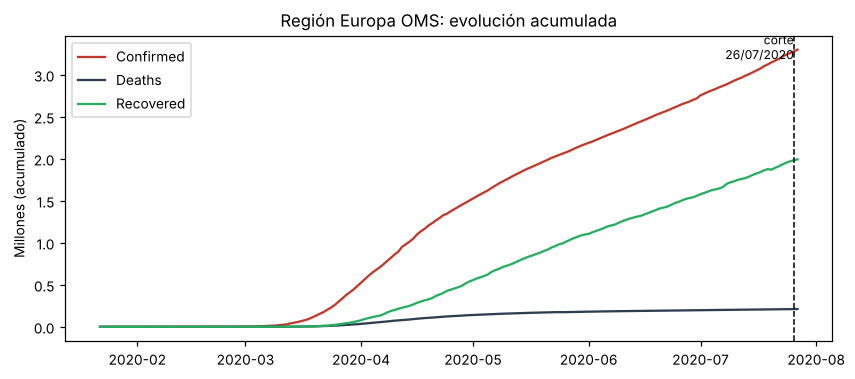

Ubicaciones con casos > 0: 29 el 22/01 vs 261 el 26/07


In [7]:
serie = (raw[raw["WHO Region"] == "Europe"].groupby("Date")[["Confirmed", "Deaths", "Recovered"]].sum())
fig, ax = plt.subplots(figsize=(9, 3.6))
for c, col in zip(serie.columns, ["#c0392b", "#2c3e50", "#27ae60"]):
    ax.plot(serie.index, serie[c] / 1e6, label=c, color=col)
ax.axvline(pd.Timestamp(FECHA_CORTE), color="k", ls="--", lw=1)
ax.text(pd.Timestamp(FECHA_CORTE), ax.get_ylim()[1] * 0.92, " corte\n 26/07/2020", ha="right", fontsize=8)
ax.set(ylabel="Millones (acumulado)", title="Región Europa OMS: evolución acumulada")
ax.legend()
guardar_fig(fig, "f1_serie_temporal_europa")
plt.show()

ubic_activas = raw[raw["Confirmed"] > 0].groupby("Date").size()
print(f"Ubicaciones con casos > 0: {ubic_activas.iloc[0]} el 22/01 vs {ubic_activas.iloc[-1]} el 26/07")

### b) Justificación de la transformación $\ln(\text{Confirmed}+1)$
**Argumento teórico.** El semivariograma $\gamma(h)=\tfrac12\,\mathbb{E}[(Z(s+h)-Z(s))^2]$ es un momento de segundo orden: depende de los **cuadrados** de las diferencias. Con una distribución de cola pesada, unos pocos valores masivos (Reino Unido, España, Italia, Alemania, Francia con más de 200 mil casos frente a microestados con decenas) dominan $\sum(z_i-z_j)^2$; el semivariograma experimental se vuelve errático, no estable bajo remuestreo, y refleja **valores atípicos y no estructura espacial**. Además, el Kriging es el mejor predictor lineal insesgado y es óptimo (media condicional) cuando el campo es aproximadamente gaussiano.

**Argumento metodológico.**
* La transformación logarítmica es estabilizadora de varianza para procesos multiplicativos: el crecimiento epidémico es aproximadamente exponencial, $C(t)\approx C_0e^{rt}$, por lo que $\ln C$ es lineal en las tasas y las diferencias $\ln C_i-\ln C_j=\ln(C_i/C_j)$ expresan **razones**.
* Reduce la asimetría y la curtosis, acercando la distribución a la normalidad que el Kriging lognormal supone.
* El $+1$ evita $\ln 0$ en ubicaciones sin casos.
* Para volver a la escala original se usa la corrección lognormal $\hat C(s_0)=\exp\{\hat Z(s_0)+\tfrac12\sigma^2_K(s_0)\}-1$, porque $\exp(\mathbb E[Z])\neq\mathbb E[\exp Z]$.

,Media,Mediana,DE,Asimetría,Curtosis exceso,Shapiro-Wilk p
Confirmed,42658.865,8255.000,76785.979,2.213,3.614,0.000
ln(Confirmed+1),8.863,9.013,2.317,-0.390,-0.278,0.357
Deaths,3740.769,304.500,9514.283,3.151,9.063,0.000
ln(Deaths+1),5.534,5.719,2.721,-0.123,-0.420,0.521


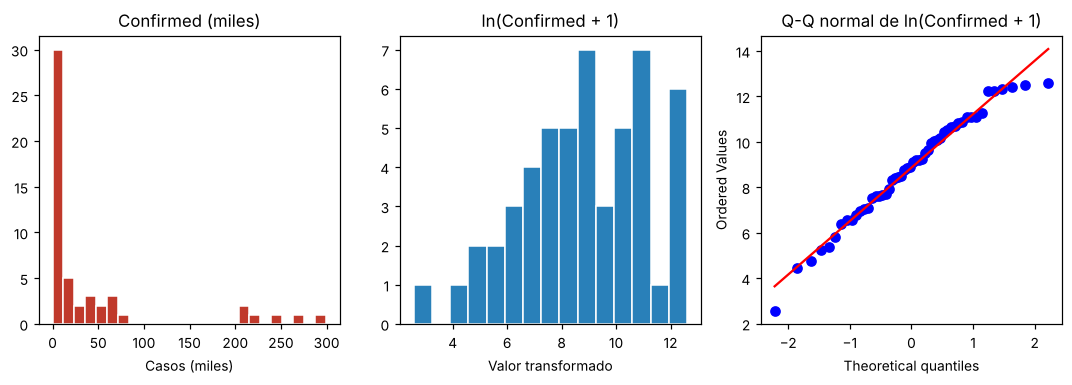

In [8]:
Z1_raw, Z2_raw = eu["Confirmed"].values, eu["Deaths"].values
z1, z2 = np.log1p(Z1_raw), np.log1p(Z2_raw)

def resumen_forma(x):
    return pd.Series({"Media": x.mean(), "Mediana": np.median(x), "DE": x.std(ddof=1),
                      "Asimetría": stats.skew(x), "Curtosis exceso": stats.kurtosis(x),
                      "Shapiro-Wilk p": stats.shapiro(x).pvalue})

tabla_forma = pd.DataFrame({"Confirmed": resumen_forma(Z1_raw), "ln(Confirmed+1)": resumen_forma(z1),
                            "Deaths": resumen_forma(Z2_raw), "ln(Deaths+1)": resumen_forma(z2)}).T
display(tabla_forma.round(3))
tabla_forma.round(4).to_csv(RES / "f1_forma_distribucion.csv")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].hist(Z1_raw / 1000, bins=25, color="#c0392b", edgecolor="w")
axes[0].set(title="Confirmed (miles)", xlabel="Casos (miles)")
axes[1].hist(z1, bins=15, color="#2980b9", edgecolor="w")
axes[1].set(title="ln(Confirmed + 1)", xlabel="Valor transformado")
stats.probplot(z1, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q normal de ln(Confirmed + 1)")
guardar_fig(fig, "f1_transformacion_log")
plt.show()

**Análisis de resultados.** La variable original presenta asimetría y curtosis muy altas y se rechaza la normalidad con contundencia. Tras $\ln(x+1)$ la asimetría se reduce casi a cero, la curtosis se normaliza y el Q-Q plot se ajusta a la recta, por lo que la modelación variográfica se realiza sobre $Z_1=\ln(\text{Confirmed}+1)$ y $Z_2=\ln(\text{Deaths}+1)$.

**Variable secundaria.** Se elige *Deaths* y no *Recovered* porque Recovered no se reporta (vale 0) en países clave como Reino Unido, Países Bajos, Suecia y Serbia, lo que introduciría ceros estructurales (no epidemiológicos) en el semivariograma cruzado.

In [9]:
sin_recov = eu.loc[(eu["Recovered"] == 0) & (eu["Confirmed"] > 1000), "Ubicacion"].tolist()
print("Ubicaciones con Recovered = 0 pese a tener más de 1000 casos:", sin_recov)
print(f"Correlación de Pearson ln(Confirmed+1) vs ln(Deaths+1): {np.corrcoef(z1, z2)[0, 1]:.3f}")

Ubicaciones con Recovered = 0 pese a tener más de 1000 casos: ['Netherlands', 'Serbia', 'Sweden', 'United Kingdom']
Correlación de Pearson ln(Confirmed+1) vs ln(Deaths+1): 0.958


### c) Homogeneización del soporte espacial (decisión metodológica adicional)
En geoestadística la variable regionalizada debe estar definida sobre un **soporte** comparable: cada dato debe representar una porción de territorio y población de magnitud similar. En este dataset cada punto agrega un país completo, por lo que conviven Alemania (83 millones de habitantes) con el Vaticano (≈ 800 habitantes) a solo decenas de kilómetros de Italia. Esos pares de **distancia muy corta y diferencia enorme** no reflejan discontinuidad epidémica sino diferencia de soporte, y se convierten en un **falso efecto pepita** (problema de cambio de soporte, *change of support problem*, y efecto del tamaño de la unidad del *MAUP*).

Por ello:
* El **análisis de patrones puntuales** (2.1) usa **todos los sitios** de reporte ($n=52$), porque allí el objeto de estudio es la localización de los sitios.
* La **modelación geoestadística** (2.2 y Fase 3) usa las ubicaciones con **población ≥ 500 000 habitantes** (OWID), con lo que se excluyen microestados y dependencias. El efecto se demuestra comparando la proporción de pepita y la autocorrelación con y sin el filtro.
* Con la población de OWID se construye además la **incidencia acumulada** $\ln(\text{casos por }100\,000\text{ hab.})$, que elimina el efecto tamaño y se usa en la Fase 4.

In [10]:
eu = eu.assign(location=eu["Ubicacion"].replace({"Holy See": "Vatican"})).merge(
    owid[["location", "population", "hospital_beds_per_thousand"]], on="location", how="left")
POB_MIN = 500_000
eu["soporte_ok"] = eu["population"] >= POB_MIN
print(f"Excluidos del análisis geoestadístico ({(~eu['soporte_ok']).sum()}):",
      ", ".join(f"{u} ({p:,.0f} hab.)" if pd.notna(p) else f"{u} (s/d)"
                for u, p in eu.loc[~eu["soporte_ok"], ["Ubicacion", "population"]].values))

# Conjunto completo (sitios de reporte) para patrones puntuales
xy_all, Z1_all = xy.copy(), Z1_raw.copy()

def resumen_estructura(xy_, z_):
    """Proporción de pepita (exponencial, WLS) e I de Moran (k = 5) para comparar soportes."""
    dmax = pdist(xy_).max() / 2
    d = pdist(xy_)
    ii, jj = np.triu_indices(len(xy_), 1)
    bordes = np.linspace(0, dmax, 13)
    h_, g_, n_ = [], [], []
    for a_, b_ in zip(bordes[:-1], bordes[1:]):
        m = (d > a_) & (d <= b_)
        if m.sum() >= 5:
            h_.append(d[m].mean()); g_.append(0.5 * ((z_[ii] - z_[jj])[m] ** 2).mean()); n_.append(m.sum())
    h_, g_, n_ = map(np.array, (h_, g_, n_))
    res = least_squares(lambda p: np.sqrt(n_) * (g_ - (p[0] + p[1] * (1 - np.exp(-3 * h_ / p[2])))),
                        [0.2 * g_.max(), 0.8 * g_.max(), dmax / 2], bounds=([0, 1e-6, 50], [3 * g_.max(), 3 * g_.max(), 4 * dmax]))
    w = KNN.from_array(xy_, k=5); w.transform = "r"
    mi = Moran(z_, w, permutations=999)
    return {"n": len(z_), "Pepita / Sill (%)": 100 * res.x[0] / (res.x[0] + res.x[1]), "I de Moran": mi.I, "p (perm.)": mi.p_sim}

m_ok = eu["soporte_ok"].values
comp_soporte = pd.DataFrame({
    "Todos los sitios": resumen_estructura(xy_all, np.log1p(Z1_all)),
    "Población ≥ 500 000": resumen_estructura(xy_all[m_ok], np.log1p(Z1_all[m_ok]))}).T
display(comp_soporte.round(3))
comp_soporte.round(4).to_csv(RES / "f1_comparacion_soporte.csv")

# Conjunto geoestadístico definitivo
eu = eu[m_ok].reset_index(drop=True)
gdf = gdf[m_ok].reset_index(drop=True)
xy = xy[m_ok]
Z1_raw, Z2_raw = eu["Confirmed"].values, eu["Deaths"].values
z1, z2 = np.log1p(Z1_raw), np.log1p(Z2_raw)
z_inc = np.log(eu["Confirmed"] / eu["population"] * 1e5).values   # ln(incidencia por 100 000 hab.)
print(f"Conjunto geoestadístico: n = {len(z1)}; corr(ln Confirmed, ln Deaths) = {np.corrcoef(z1, z2)[0, 1]:.3f}")

flujo = pd.DataFrame({
    "Etapa": ["Registros del archivo", "Ubicaciones en la fecha de corte", "Región Europa OMS",
              "Dentro de la ventana de EPSG:3035", "Con población ≥ 500 000 (análisis geoestadístico)"],
    "Registros": [len(raw), len(corte), int((corte["WHO Region"] == "Europe").sum()), len(xy_all), len(z1)]})
display(flujo)
flujo.to_csv(RES / "f1_flujo_registros.csv", index=False)

Excluidos del análisis geoestadístico (10): Andorra (79,843 hab.), Faroe Islands (53,117 hab.), Holy See (808 hab.), Iceland (372,903 hab.), Liechtenstein (39,355 hab.), Monaco (36,491 hab.), San Marino (33,690 hab.), Channel Islands (s/d), Gibraltar (32,677 hab.), Isle of Man (84,534 hab.)


,n,Pepita / Sill (%),I de Moran,p (perm.)
Todos los sitios,52.0,61.674,-0.028,0.498
Población ≥ 500 000,42.0,23.313,0.086,0.087


Conjunto geoestadístico: n = 42; corr(ln Confirmed, ln Deaths) = 0.957


,Etapa,Registros
0,Registros del archivo,49068
1,Ubicaciones en la fecha de corte,261
2,Región Europa OMS,80
3,Dentro de la ventana de EPSG:3035,52
4,Con población ≥ 500 000 (análisis geoestadístico),42


**Análisis de resultados.** Con los 52 sitios la proporción pepita/meseta es ≈ 62 % y la I de Moran es prácticamente nula (≈ −0,03; p ≈ 0,50): la estructura espacial queda enmascarada por diez unidades de soporte minúsculo (Vaticano, San Marino, Mónaco, Liechtenstein, Andorra, Gibraltar, Isla de Man, Islas Feroe, Islas del Canal e Islandia). Al homogeneizar el soporte ($n=42$) la pepita relativa cae a ≈ 23 % (dependencia espacial **moderada a fuerte**) y la I de Moran se vuelve positiva. La decisión está, por tanto, respaldada empíricamente y no solo por argumento teórico.

---
# Fase 2. Análisis Exploratorio de Datos Espaciales (AEDE) e IDW

## 2.1 Análisis de patrones puntuales

### a) Estimación de densidad kernel (KDE) y ancho de banda
Sea $\{s_1,\dots,s_n\}\subset W$ un patrón puntual en la ventana $W$. El estimador kernel de la intensidad $\lambda(s)$ es

$$\hat\lambda_h(s)=\frac{1}{e_h(s)}\sum_{i=1}^{n} w_i\,\frac{1}{h^2}K\!\left(\frac{\lVert s-s_i\rVert}{h}\right),\qquad
K(u)=\frac{1}{2\pi}e^{-u^2/2},$$

donde $K$ es un kernel simétrico que integra 1, $h$ es el **ancho de banda**, $w_i$ es un peso opcional (aquí, los casos confirmados para obtener la intensidad de *casos*; $w_i=1$ para la intensidad de *sitios*) y $e_h(s)$ es una corrección de borde (Diggle, 1985). Aquí se usa $e_h(s)=1$: el sesgo de borde afecta solo a la franja costera y no altera la localización de los máximos.

**Efecto del ancho de banda.** $h$ controla el compromiso sesgo-varianza:
* $h$ **pequeño**: superficie rugosa con un pico por punto; detecta *hotspots* locales pero muchos son artefactos de la ubicación del centroide (alta varianza).
* $h$ **grande**: superficie suavizada que fusiona focos vecinos en una sola mancha regional; los *hotspots* reales se diluyen (alto sesgo).
* Una regla de referencia es la de Silverman en 2D, $h_{opt}=\sigma\,n^{-1/6}$ con $\sigma=\sqrt{(\sigma_x^2+\sigma_y^2)/2}$. A continuación se comparan $h_{opt}/2$, $h_{opt}$ y $2h_{opt}$.

Grilla 189×161 celdas de 25 km; nodos sobre tierra: 14,167
Ancho de banda de Silverman: h_opt = 467 km


,Ancho,h (km),Máx. casos/100 km²,Área con > 50 % del máximo (km²),Coef. variación de la superficie
0,h/2,233.57,89.94,1094375,1.10
1,h óptimo,467.13,38.12,2577500,0.77
2,2h,934.26,21.35,4219375,0.54


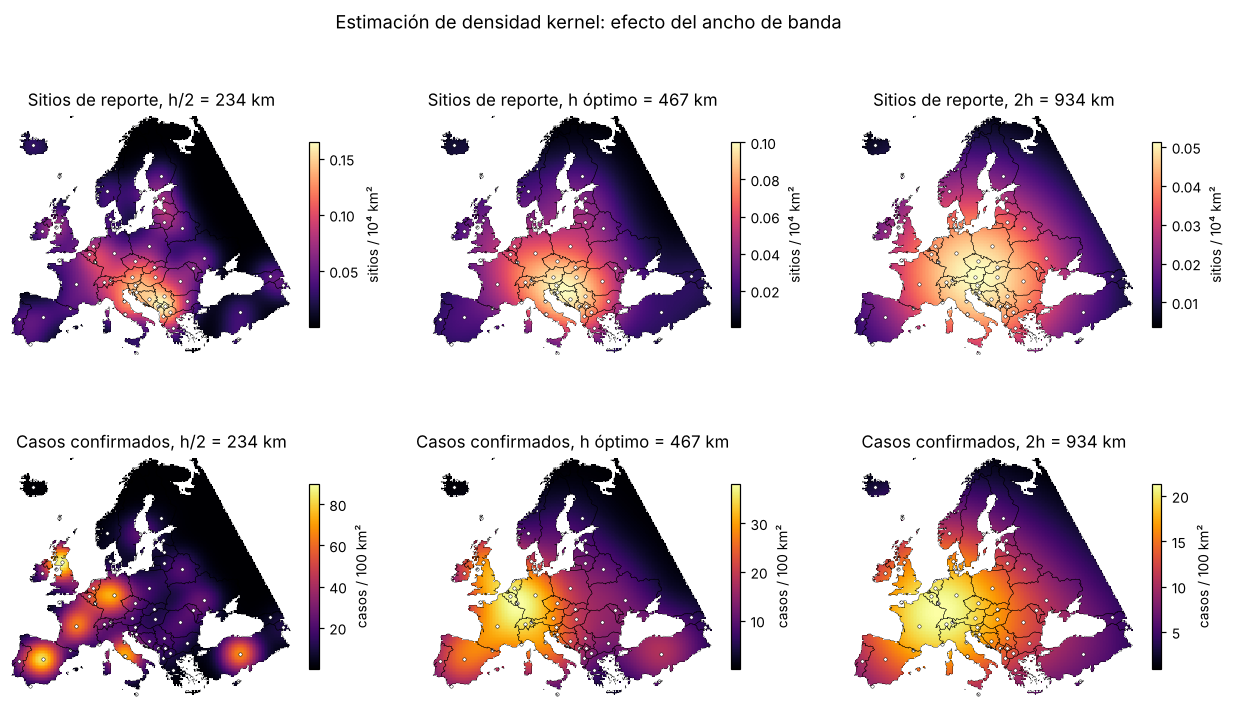

In [11]:
# Grilla de evaluación en km (compartida por KDE, IDW y Kriging)
xmin, ymin, xmax, ymax = paises_km.total_bounds
gx = np.arange(np.floor(xmin), xmax + CELDA_KM, CELDA_KM)
gy = np.arange(np.floor(ymin), ymax + CELDA_KM, CELDA_KM)
GX, GY = np.meshgrid(gx, gy)
MASK = contains_xy(region_km, GX, GY)
nodos = np.column_stack([GX[MASK], GY[MASK]])
EXTENT = (gx[0] - CELDA_KM / 2, gx[-1] + CELDA_KM / 2, gy[0] - CELDA_KM / 2, gy[-1] + CELDA_KM / 2)
print(f"Grilla {GX.shape[1]}×{GX.shape[0]} celdas de {CELDA_KM} km; nodos sobre tierra: {len(nodos):,}")

def a_grilla(valores):
    """Devuelve una matriz 2D (NaN fuera de la máscara) a partir de valores en los nodos."""
    Z = np.full(GX.shape, np.nan)
    Z[MASK] = valores
    return Z

def mapa(ax, valores, titulo, cmap="viridis", etiqueta="", vmin=None, vmax=None, norm=None, puntos=True):
    im = ax.imshow(a_grilla(valores), origin="lower", extent=EXTENT, cmap=cmap,
                   vmin=vmin, vmax=vmax, norm=norm, interpolation="nearest")
    paises_km.boundary.plot(ax=ax, color="k", lw=0.25)
    if puntos is not False:
        pts = xy if puntos is True else puntos
        ax.scatter(pts[:, 0], pts[:, 1], s=5, c="white", edgecolor="k", lw=0.3)
    ax.set_title(titulo)
    ax.set_axis_off()
    plt.colorbar(im, ax=ax, shrink=0.65, label=etiqueta)
    return im

def kde_gauss(puntos, pesos, h, destino):
    """KDE gaussiano isotrópico; devuelve intensidad por km²."""
    d2 = cdist(destino, puntos, "sqeuclidean")
    return (np.exp(-d2 / (2 * h ** 2)) @ pesos) / (2 * np.pi * h ** 2)

sigma = np.sqrt((xy_all[:, 0].var(ddof=1) + xy_all[:, 1].var(ddof=1)) / 2)
h_opt = sigma * len(xy_all) ** (-1 / 6)
anchos = {"h/2": h_opt / 2, "h óptimo": h_opt, "2h": 2 * h_opt}
print(f"Ancho de banda de Silverman: h_opt = {h_opt:.0f} km")

fig, axes = plt.subplots(2, 3, figsize=(14, 7.4))
kde_tabla = []
for k, (nombre, h) in enumerate(anchos.items()):
    lam_sitios = kde_gauss(xy_all, np.ones(len(xy_all)), h, nodos) * 1e4        # sitios por 10 000 km²
    lam_casos = kde_gauss(xy_all, Z1_all.astype(float), h, nodos) * 1e2         # casos por 100 km²
    kde_tabla.append({"Ancho": nombre, "h (km)": h, "Máx. casos/100 km²": lam_casos.max(),
                      "Área con > 50 % del máximo (km²)": (lam_casos > 0.5 * lam_casos.max()).sum() * CELDA_KM ** 2,
                      "Coef. variación de la superficie": lam_casos.std() / lam_casos.mean()})
    mapa(axes[0, k], lam_sitios, f"Sitios de reporte, {nombre} = {h:.0f} km", "magma", "sitios / 10⁴ km²", puntos=xy_all)
    mapa(axes[1, k], lam_casos, f"Casos confirmados, {nombre} = {h:.0f} km", "inferno", "casos / 100 km²", puntos=xy_all)
kde_tabla = pd.DataFrame(kde_tabla)
display(kde_tabla.round(2))
kde_tabla.round(3).to_csv(RES / "f2_kde_anchos.csv", index=False)
fig.suptitle("Estimación de densidad kernel: efecto del ancho de banda", fontsize=12)
guardar_fig(fig, "f2_kde_anchos_banda")
plt.show()

**Análisis de resultados.** El ancho de Silverman es $h_{opt}\approx 467$ km. Al pasar de $h/2$ (234 km) a $2h$ (934 km) la intensidad máxima de casos cae de ≈ 90 a ≈ 21 casos por 100 km², el área con intensidad superior al 50 % del máximo se cuadruplica (de ≈ 1,1 a ≈ 4,2 millones de km²) y el coeficiente de variación de la superficie baja de 1,10 a 0,54. Con $h/2$ cada país aparece como un foco aislado y los microestados generan picos de intensidad de *sitios* que no son epidemiológicos. Con $h_{opt}$ la intensidad de *casos* revela un corredor de concentración en Europa occidental (Reino Unido, Francia, España, Italia, Alemania, Bélgica). Con $2h$ ese corredor se funde en una mancha única que ya no distingue focos nacionales. El ancho de banda decide, por tanto, si un *hotspot* se identifica a escala nacional ($h$ pequeño) o regional ($h$ grande); en vigilancia epidemiológica conviene reportar al menos dos escalas.

### b) Prueba de Completa Aleatoriedad Espacial (CSR)
**Hipótesis.** $H_0$: los sitios son una realización de un proceso de Poisson homogéneo en $W$ (CSR), con intensidad constante $\lambda$ e independencia entre puntos. $H_1$: el patrón es **agrupado** (o regular).

**Función $G$ (vecino más cercano).** $G(r)=P(D\le r)$, con $D$ la distancia de un punto a su vecino más cercano. Bajo CSR, $G_{CSR}(r)=1-\exp(-\lambda\pi r^2)$. Si $\hat G(r)>G_{CSR}(r)$ para $r$ pequeños, hay agrupamiento.

**Función $K$ de Ripley.** $K(r)=\lambda^{-1}\,\mathbb{E}[\text{nº de puntos adicionales a distancia}\le r\text{ de un punto típico}]$, estimada por
$$\hat K(r)=\frac{|W|}{n(n-1)}\sum_{i\neq j}\mathbb{1}(d_{ij}\le r).$$
Bajo CSR, $K(r)=\pi r^2$. Se usa la transformación estabilizadora $L(r)=\sqrt{K(r)/\pi}$, y se grafica $L(r)-r$: positivo indica agrupamiento, negativo regularidad (inhibición).

**Funciones complementarias.** $F(r)$ (*empty space*) es la distribución de la distancia desde un punto arbitrario de $W$ al sitio más cercano; bajo CSR, $F(r)=G(r)=1-e^{-\lambda\pi r^2}$. La función $J(r)=\dfrac{1-G(r)}{1-F(r)}$ vale 1 bajo CSR, $J<1$ en patrones agrupados y $J>1$ en regulares (van Lieshout y Baddeley, 1996). $G$ y $F$ describen la escala corta (vecino más cercano), mientras que $K$ y $L$ acumulan información de todas las escalas.

**Procedimiento Monte Carlo.** Se simulan $m=199$ patrones CSR con el mismo $n$ dentro de la misma ventana $W$ (el territorio terrestre), lo que compensa los efectos de borde, y se construyen envolventes puntuales (mín, máx). El contraste global usa el estadístico de máxima desviación absoluta $T=\max_r|\hat L(r)-\bar L_{CSR}(r)|$; el p-valor es $(1+\#\{T_k\ge T_{obs}\})/(m+1)$. Se complementa con el índice de Clark-Evans $R=\bar d_{obs}/(0{,}5/\sqrt{\lambda})$ ($R<1$: agrupamiento).

,Estadístico,Valor
0,n,5.200000e+01
1,Área de W (km²),8.851064e+06
2,Intensidad λ (puntos/10⁶ km²),5.875000e+00
3,Distancia media al vecino (km),2.780575e+02
4,Clark-Evans R,1.347900e+00
5,Clark-Evans z,4.799900e+00
6,Clark-Evans p (bilateral),0.000000e+00
7,MAD T_obs (L),1.316362e+02
8,MAD p-valor Monte Carlo,2.000000e-02


L(r) por ENCIMA de la envolvente (agrupamiento) en r ∈ [-, -] km
L(r) por DEBAJO de la envolvente (regularidad) en r ∈ [-, -] km


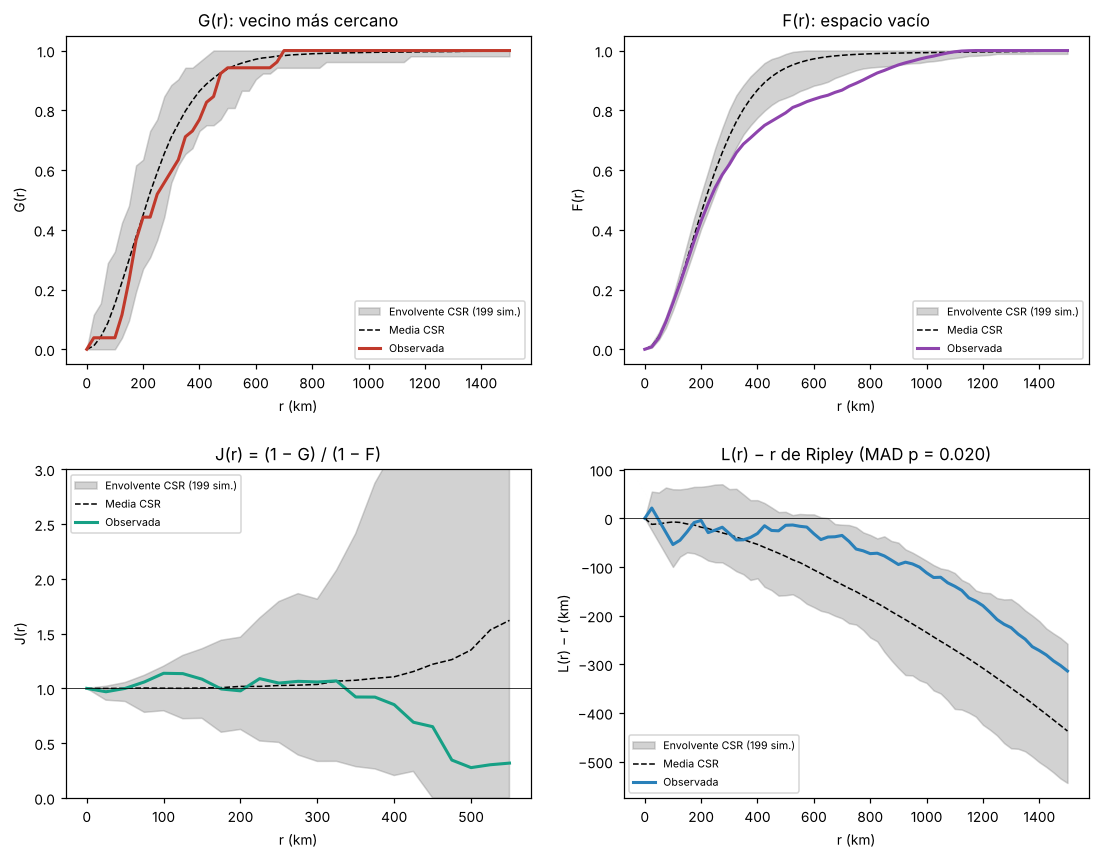

In [12]:
AREA_W = region_km.area
N_SIM = 199
radios = np.linspace(0, 1500, 61)

def simular_csr(n, poligono, rng):
    bx0, by0, bx1, by1 = poligono.bounds
    pts = np.empty((0, 2))
    while len(pts) < n:
        cand = np.column_stack([rng.uniform(bx0, bx1, 4 * n), rng.uniform(by0, by1, 4 * n)])
        pts = np.vstack([pts, cand[contains_xy(poligono, cand[:, 0], cand[:, 1])]])
    return pts[:n]

def funcion_g(pts, r):
    nn = cKDTree(pts).query(pts, k=2)[0][:, 1]
    return np.array([(nn <= ri).mean() for ri in r]), nn

def funcion_l(pts, r, area):
    n = len(pts)
    d = pdist(pts)
    k = np.array([2 * (d <= ri).sum() for ri in r]) * area / (n * (n - 1))
    return np.sqrt(k / np.pi)

PUNTOS_F = simular_csr(2000, region_km, np.random.default_rng(1))   # puntos de prueba para F(r)

def funcion_f(pts, r):
    d = cKDTree(pts).query(PUNTOS_F, k=1)[0]
    return np.array([(d <= ri).mean() for ri in r])

G_obs, nn_obs = funcion_g(xy_all, radios)
F_obs = funcion_f(xy_all, radios)
L_obs = funcion_l(xy_all, radios, AREA_W)
sims = [simular_csr(len(xy_all), region_km, rng) for _ in range(N_SIM)]
G_sim = np.array([funcion_g(s, radios)[0] for s in sims])
F_sim = np.array([funcion_f(s, radios) for s in sims])
L_sim = np.array([funcion_l(s, radios, AREA_W) for s in sims])
with np.errstate(divide="ignore", invalid="ignore"):
    J_obs = (1 - G_obs) / (1 - F_obs)
    J_sim = (1 - G_sim) / (1 - F_sim)

L_media = L_sim.mean(0)
T_obs = np.max(np.abs(L_obs - L_media))
T_sim = np.array([np.max(np.abs(Ls - L_media)) for Ls in L_sim])
p_mad = (1 + (T_sim >= T_obs).sum()) / (N_SIM + 1)

lam = len(xy_all) / AREA_W
R_ce = nn_obs.mean() / (0.5 / np.sqrt(lam))
se_ce = 0.26136 / np.sqrt(len(xy_all) * lam)
z_ce = (nn_obs.mean() - 0.5 / np.sqrt(lam)) / se_ce
csr_tabla = pd.DataFrame({
    "Estadístico": ["n", "Área de W (km²)", "Intensidad λ (puntos/10⁶ km²)", "Distancia media al vecino (km)",
                    "Clark-Evans R", "Clark-Evans z", "Clark-Evans p (bilateral)", "MAD T_obs (L)",
                    "MAD p-valor Monte Carlo"],
    "Valor": [len(xy_all), AREA_W, lam * 1e6, nn_obs.mean(), R_ce, z_ce, 2 * stats.norm.sf(abs(z_ce)), T_obs, p_mad]})
display(csr_tabla.round(4))
csr_tabla.to_csv(RES / "f2_csr.csv", index=False)

# Escalas donde la curva observada sale de la envolvente
fuera_L_sup = radios[(L_obs > L_sim.max(0)) & (radios > 0)]
fuera_L_inf = radios[(L_obs < L_sim.min(0)) & (radios > 0)]
print(f"L(r) por ENCIMA de la envolvente (agrupamiento) en r ∈ [{fuera_L_sup.min() if len(fuera_L_sup) else '-'}, "
      f"{fuera_L_sup.max() if len(fuera_L_sup) else '-'}] km")
print(f"L(r) por DEBAJO de la envolvente (regularidad) en r ∈ [{fuera_L_inf.min() if len(fuera_L_inf) else '-'}, "
      f"{fuera_L_inf.max() if len(fuera_L_inf) else '-'}] km")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.subplots_adjust(hspace=0.32)
def panel(ax, obs, sim, titulo, ylab, color, ref=None):
    ax.fill_between(radios, np.nanmin(sim, 0), np.nanmax(sim, 0), color="grey", alpha=0.35, label="Envolvente CSR (199 sim.)")
    ax.plot(radios, np.nanmean(sim, 0), "k--", lw=1, label="Media CSR")
    ax.plot(radios, obs, color=color, lw=2, label="Observada")
    if ref is not None:
        ax.axhline(ref, color="k", lw=0.5)
    ax.set(xlabel="r (km)", ylabel=ylab, title=titulo)
    ax.legend(fontsize=7)
panel(axes[0, 0], G_obs, G_sim, "G(r): vecino más cercano", "G(r)", "#c0392b")
panel(axes[0, 1], F_obs, F_sim, "F(r): espacio vacío", "F(r)", "#8e44ad")
rJ = radios <= 550                      # para r mayor, F_CSR → 1 y J no está definida
radios_full = radios
radios = radios_full[rJ]
panel(axes[1, 0], J_obs[rJ], J_sim[:, rJ], "J(r) = (1 − G) / (1 − F)", "J(r)", "#16a085", ref=1)
radios = radios_full
axes[1, 0].set_ylim(0, 3)
panel(axes[1, 1], L_obs - radios, L_sim - radios, f"L(r) − r de Ripley (MAD p = {p_mad:.3f})", "L(r) − r (km)", "#2980b9", ref=0)
guardar_fig(fig, "f2_csr_G_F_J_L")
plt.show()

**Análisis de resultados.** Se **rechaza CSR**. El índice de Clark-Evans $R\approx1{,}35$ ($z\approx4{,}8$, $p<0{,}001$) indica **regularidad a escala de vecino más cercano**: la distancia media al vecino (≈ 278 km) supera la esperada bajo CSR, lo que es coherente con un proceso de **inhibición** (un centroide por país; dos países no pueden "ocupar" el mismo lugar). $G(r)$ queda por debajo de la media CSR entre 100 y 450 km y $J(r)>1$ en distancias cortas, señal de regularidad. A escala grande el patrón es **agregado**: $F(r)$ sale de la envolvente por debajo entre ≈ 400 y 1000 km (grandes espacios vacíos: Rusia europea, norte de Escandinavia, Anatolia), $J(r)<1$ desde ≈ 350 km y $L(r)-r$ queda sobre la media CSR a partir de ≈ 600 km. El contraste global MAD confirma la desviación ($p=0{,}02$).

**Implicación metodológica:** el patrón de sitios refleja la geografía política, no la epidemia. Los sitios deben tratarse como un **diseño de muestreo fijo** y el análisis epidemiológico debe recaer en el **atributo** (Confirmed, Deaths) mediante geoestadística. La concentración de sitios en Europa occidental anticipa además mayor incertidumbre de predicción en el este (muestreo preferencial; Diggle, Menezes y Su, 2010).

**Complemento: autocorrelación del atributo y hotspots locales.** CSR evalúa la *ubicación* de los sitios; la autocorrelación evalúa si los *valores* en sitios cercanos se parecen (primera ley de Tobler: "todo está relacionado con todo, pero las cosas cercanas están más relacionadas que las distantes").

* **I de Moran global:** $I=\dfrac{n}{S_0}\,\dfrac{\sum_i\sum_j w_{ij}(z_i-\bar z)(z_j-\bar z)}{\sum_i (z_i-\bar z)^2}$, con $S_0=\sum_{ij}w_{ij}$.
* **LISA (Moran local):** $I_i=\dfrac{z_i-\bar z}{m_2}\sum_j w_{ij}(z_j-\bar z)$, clasifica cada sitio en Alto-Alto (hotspot), Bajo-Bajo (coldspot) o atípicos Alto-Bajo / Bajo-Alto (Anselin, 1995).
* **Getis-Ord $G_i^*$:** $G_i^*=\dfrac{\sum_j w_{ij}z_j-\bar z\sum_j w_{ij}}{s\sqrt{[n\sum_j w_{ij}^2-(\sum_j w_{ij})^2]/(n-1)}}$; $G_i^*>1{,}96$ indica concentración de valores altos (Getis y Ord, 1992).

Pesos: 5 vecinos más cercanos estandarizados por fila; inferencia por 999 permutaciones condicionales. Se analiza el conjunto geoestadístico ($n$ con población ≥ 500 000).

,Variable,I,E[I],z (perm.),p (perm.)
0,ln(Confirmed+1),0.0856,-0.0244,1.2788,0.113
1,ln(Deaths+1),0.1390,-0.0244,1.8969,0.050
2,ln(incidencia/100k),0.1078,-0.0244,1.5287,0.078


,Ubicacion,LISA,Gi*_z,Gi*_p
2,Austria,Alto-Bajo,-0.976,0.002
3,Belarus,Alto-Bajo,-0.491,0.032
9,Czechia,Bajo-Bajo,-0.679,0.052
13,France,Alto-Alto,0.820,0.015
18,Ireland,Alto-Alto,0.822,0.023
24,Moldova,Alto-Bajo,-0.543,0.024
29,Poland,Bajo-Bajo,-1.051,0.006
30,Portugal,Alto-Alto,0.793,0.025
33,Slovakia,Bajo-Bajo,-0.996,0.024
35,Spain,Alto-Alto,0.909,0.008


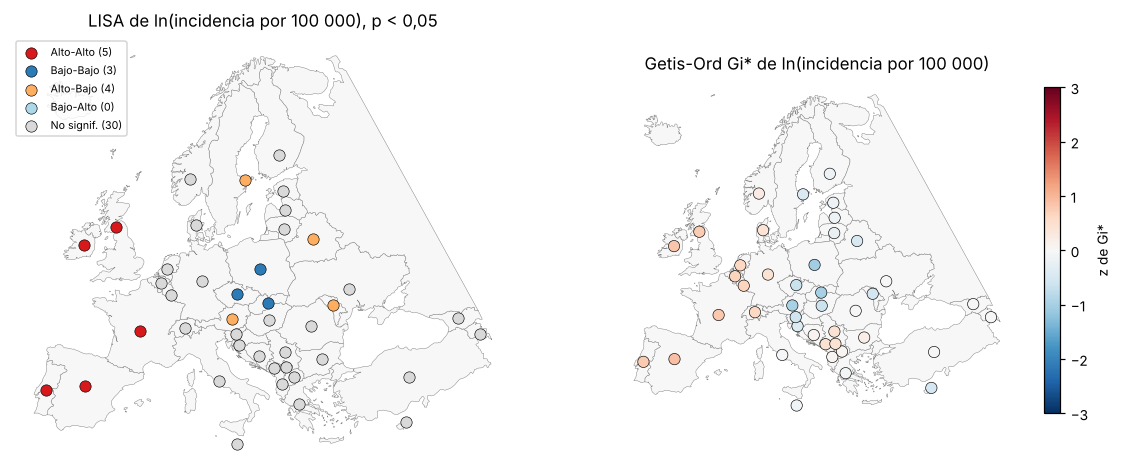

In [13]:
from esda.moran import Moran_Local
from esda.getisord import G_Local

W_knn = KNN.from_array(xy, k=5)
W_knn.transform = "r"
moran_res = []
for nombre, z in [("ln(Confirmed+1)", z1), ("ln(Deaths+1)", z2), ("ln(incidencia/100k)", z_inc)]:
    mi = Moran(z, W_knn, permutations=999)
    moran_res.append({"Variable": nombre, "I": mi.I, "E[I]": mi.EI, "z (perm.)": mi.z_sim, "p (perm.)": mi.p_sim})
moran_tabla = pd.DataFrame(moran_res)
display(moran_tabla.round(4))
moran_tabla.round(4).to_csv(RES / "f2_moran.csv", index=False)

np.random.seed(SEED)
lisa = Moran_Local(z_inc, W_knn, permutations=999)
gi = G_Local(z_inc, W_knn, star=True, permutations=999)
etiquetas = {1: "Alto-Alto", 2: "Bajo-Alto", 3: "Bajo-Bajo", 4: "Alto-Bajo"}
eu["LISA"] = [etiquetas[q] if p < 0.05 else "No signif." for q, p in zip(lisa.q, lisa.p_sim)]
eu["Gi*_z"], eu["Gi*_p"] = gi.Zs, gi.p_sim
display(eu.loc[(eu["LISA"] != "No signif.") | (eu["Gi*_p"] < 0.05), ["Ubicacion", "LISA", "Gi*_z", "Gi*_p"]].round(3))
eu[["Ubicacion", "LISA", "Gi*_z", "Gi*_p"]].round(4).to_csv(RES / "f2_lisa_getis.csv", index=False)

colores = {"Alto-Alto": "#d7191c", "Bajo-Bajo": "#2c7bb6", "Alto-Bajo": "#fdae61", "Bajo-Alto": "#abd9e9", "No signif.": "#d9d9d9"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax in axes:
    paises_km.plot(ax=ax, color="#f7f7f7", edgecolor="grey", lw=0.3)
    ax.set_axis_off()
for k, v in colores.items():
    m = eu["LISA"] == k
    axes[0].scatter(xy[m, 0], xy[m, 1], c=v, s=55, edgecolor="k", lw=0.4, label=f"{k} ({m.sum()})")
axes[0].legend(fontsize=7, loc="upper left")
axes[0].set_title("LISA de ln(incidencia por 100 000), p < 0,05")
s = axes[1].scatter(xy[:, 0], xy[:, 1], c=gi.Zs, cmap="RdBu_r", vmin=-3, vmax=3, s=55, edgecolor="k", lw=0.4)
plt.colorbar(s, ax=axes[1], shrink=0.7, label="z de Gi*")
axes[1].set_title("Getis-Ord Gi* de ln(incidencia por 100 000)")
guardar_fig(fig, "f2_lisa_getis")
plt.show()

**Análisis de resultados.** La autocorrelación global es positiva pero modesta: $I\approx0{,}14$ para Deaths ($p\approx0{,}05$), $I\approx0{,}11$ para la incidencia ($p\approx0{,}08$) e $I\approx0{,}09$ para Confirmed ($p\approx0{,}11$). La escasa significancia global con $n=42$ esconde patrones **locales** claros:
* **Alto-Alto (hotspot):** España, Portugal, Francia, Reino Unido e Irlanda forman un **corredor atlántico occidental** de alta incidencia.
* **Bajo-Bajo (coldspot):** Polonia, Eslovaquia y Chequia, en Europa central, con incidencias bajas en la primera ola.
* **Atípicos Alto-Bajo:** Suecia (estrategia sin confinamiento estricto, rodeada de vecinos nórdicos de baja incidencia), Bielorrusia y Moldavia (medidas tardías o laxas) y Austria.

Estos resultados justifican modelar la dependencia espacial (Fase 3) y anticipan que la heterogeneidad responde tanto a la distancia como a decisiones nacionales de política sanitaria (fuente de efecto pepita).

## 2.2 Interpolación determinística: IDW

### a) Formulación
Para una localización no muestreada $s_0$ y $Z(s_i)=\ln(\text{Confirmed}_i+1)$:
$$\hat Z_{IDW}(s_0)=\sum_{i=1}^{n}\lambda_i(s_0)\,Z(s_i),\qquad
\lambda_i(s_0)=\frac{d(s_0,s_i)^{-p}}{\sum_{k=1}^{n} d(s_0,s_k)^{-p}},$$
con $d(\cdot,\cdot)$ la distancia euclidiana **proyectada** (km) y $p>0$ el parámetro de potencia. Si $s_0=s_i$, $\hat Z(s_0)=Z(s_i)$ (interpolador exacto). Los pesos son positivos y suman 1, por lo que $\hat Z(s_0)\in[\min Z,\max Z]$.

### b) Efecto de $p$ y limitaciones
* **$p\to 0$**: todos los pesos se igualan y $\hat Z\to\bar Z$ (superficie plana, sobresuavizada).
* **$p$ pequeño (≈1)**: influencia de puntos lejanos, superficie suave.
* **$p$ grande (≥ 4)**: domina el vecino más cercano; con $p\to\infty$ IDW tiende a polígonos de Voronoi (superficie escalonada) y aparecen "ojos de buey" (*bull's eyes*) alrededor de cada dato.
* **$p=2$** es el valor convencional; aquí se elige por validación cruzada *leave-one-out*.

**Limitaciones frente a la regresión espacial y el Kriging:**
1. $p$ es arbitrario: no se estima a partir de la estructura de dependencia de los datos (no hay semivariograma).
2. No produce **medida de incertidumbre**: no hay varianza de predicción.
3. Ignora la **redundancia** entre datos agrupados (los microestados cerca de Italia reciben pesos acumulados como si fueran información independiente); el Kriging la corrige mediante $\Gamma$.
4. Es **isotrópico** y no admite tendencias ni covariables (la regresión espacial y el Kriging universal sí).
5. No puede extrapolar fuera del rango de los datos y genera artefactos de *bull's eye*.

,p,ME,MAE,RMSE,"r(obs,pred)"
0,0.5,-0.0446,1.4305,1.6943,-0.0302
1,1.0,-0.0966,1.3802,1.6643,0.1723
2,1.5,-0.1508,1.3528,1.6552,0.2183
3,2.0,-0.1994,1.3472,1.6849,0.2210
4,2.5,-0.2374,1.3768,1.7489,0.2104
5,3.0,-0.2667,1.4145,1.8257,0.1961
6,4.0,-0.3120,1.4965,1.9580,0.1673
7,6.0,-0.3668,1.5927,2.0843,0.1338


Potencia óptima por LOO: p = 1.5


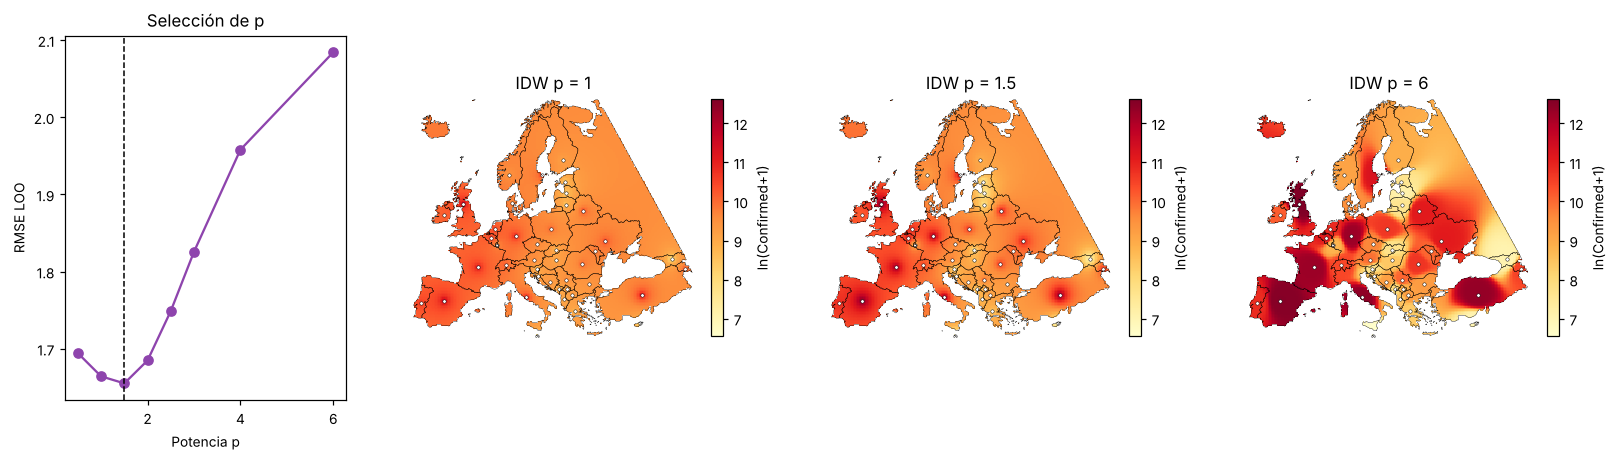

In [14]:
def idw(xy_obs, z_obs, destino, p):
    d = cdist(destino, xy_obs)
    exacto = d < 1e-9
    w = 1.0 / np.maximum(d, 1e-9) ** p
    w[exacto.any(1)] = exacto[exacto.any(1)].astype(float)
    return (w @ z_obs) / w.sum(1)

def metricas(obs, pred, var=None):
    e = pred - obs
    out = {"ME": e.mean(), "MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()),
           "r(obs,pred)": np.corrcoef(obs, pred)[0, 1]}
    if var is not None:
        zs = e / np.sqrt(var)
        out.update({"MSE estandarizado": zs.mean(), "RMSS": np.sqrt((zs ** 2).mean())})
    return out

def loo_idw(p):
    pred = np.array([idw(np.delete(xy, k, 0), np.delete(z1, k), xy[[k]], p)[0] for k in range(len(z1))])
    return pred

potencias = [0.5, 1, 1.5, 2, 2.5, 3, 4, 6]
cv_idw = pd.DataFrame([{"p": p, **metricas(z1, loo_idw(p))} for p in potencias]).round(4)
p_opt = cv_idw.loc[cv_idw["RMSE"].idxmin(), "p"]
display(cv_idw)
cv_idw.to_csv(RES / "f2_idw_validacion_cruzada.csv", index=False)
print(f"Potencia óptima por LOO: p = {p_opt}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.3), gridspec_kw={"width_ratios": [0.8, 1, 1, 1]})
axes[0].plot(cv_idw["p"], cv_idw["RMSE"], "o-", color="#8e44ad")
axes[0].axvline(p_opt, ls="--", color="k", lw=1)
axes[0].set(xlabel="Potencia p", ylabel="RMSE LOO", title="Selección de p")
vmin, vmax = z1.min(), z1.max()
for ax, p in zip(axes[1:], [1, p_opt, 6]):
    mapa(ax, idw(xy, z1, nodos, p), f"IDW p = {p:g}", "YlOrRd", "ln(Confirmed+1)", vmin, vmax)
guardar_fig(fig, "f2_idw_potencias")
plt.show()
z1_idw = idw(xy, z1, nodos, p_opt)

**Análisis de resultados.** La validación cruzada elige $p=1{,}5$ (RMSE ≈ 1,655), menor que el $p=2$ convencional. Con $p=1$ la superficie es suave pero arrastra los valores altos de los grandes países hacia zonas sin datos; con $p=6$ el mapa se vuelve un mosaico tipo Voronoi con discontinuidades en las fronteras y el RMSE sube a ≈ 2,08 (+26 %). El sesgo medio crece con $p$ (de −0,04 a −0,37), porque los puntos aislados con valores bajos dominan sus vecindades. Aun con el $p$ óptimo, IDW no informa cuán confiable es cada predicción, lo que motiva el enfoque geoestadístico de la Fase 3.

---
# Fase 3. Modelación geoestadística: Kriging y Cokriging

## 3.1 Análisis variográfico

**Marco.** $\{Z(s): s\in D\subset\mathbb R^2\}$ es una función aleatoria (variable regionalizada). Se distinguen tres niveles de estacionariedad: **fuerte** (invarianza de todas las distribuciones finito-dimensionales ante traslaciones), **de segundo orden** ($\mathbb E[Z(s)]=\mu$ y $\operatorname{Cov}[Z(s),Z(s+h)]=C(h)$) e **intrínseca** (solo los incrementos son estacionarios). Bajo segundo orden se cumple $\gamma(h)=C(0)-C(h)$, de modo que la meseta es la varianza $C(0)$ y el semivariograma es la imagen especular del covariograma; la hipótesis intrínseca es más débil y es la que requiere el Kriging Ordinario.

### a) Semivariograma experimental y parámetros
Bajo **estacionariedad intrínseca**, $\mathbb{E}[Z(s+h)-Z(s)]=0$ y $\operatorname{Var}[Z(s+h)-Z(s)]=2\gamma(h)$. El estimador de Matheron para $Z=\ln(\text{Confirmed}+1)$ es
$$\hat\gamma(h)=\frac{1}{2|N(h)|}\sum_{(i,j)\in N(h)}\big[Z(s_i)-Z(s_j)\big]^2,\qquad
N(h)=\{(i,j):\ \lVert s_i-s_j\rVert\in(h-\delta,\,h+\delta]\}.$$

| Parámetro | Definición | Significado físico-epidemiológico |
|---|---|---|
| **Nugget** $c_0$ | $\lim_{h\to0^+}\gamma(h)$ | Variabilidad a distancias menores que la mínima entre sitios más error de medida: diferencias de política de testeo, subregistro y criterios de reporte entre países vecinos. Un $c_0$ alto indica que países contiguos pueden tener cargas epidémicas muy distintas. |
| **Sill** $c_0+c$ | $\lim_{h\to\infty}\gamma(h)\approx\operatorname{Var}[Z]$ | Variabilidad total de la carga epidémica (log) entre ubicaciones independientes. $c$ (meseta parcial) es la porción con estructura espacial. |
| **Range** $a$ | Distancia a la que $\gamma(h)$ alcanza (o llega al 95 % de) la meseta | Escala espacial de **contagio y movilidad**: dentro de $a$ km la carga de un país informa sobre la de sus vecinos (corredores de transporte, fronteras abiertas Schengen); más allá, son independientes. |

La razón $c_0/(c_0+c)$ mide la dependencia espacial: < 25 % fuerte, 25-75 % moderada, > 75 % débil (Cambardella et al., 1994).

### b) Modelos teóricos
Con $c_0$ el nugget, $c$ la meseta parcial y $a$ el **alcance práctico**:

| Modelo | $\gamma(h)$, $h>0$ | Comportamiento en el origen | Meseta |
|---|---|---|---|
| Esférico | $c_0+c\left[\tfrac32\tfrac{h}{a}-\tfrac12\left(\tfrac{h}{a}\right)^3\right]$ si $h\le a$; $c_0+c$ si $h>a$ | Lineal | Alcanzada exactamente en $a$ |
| Exponencial | $c_0+c\left[1-\exp(-3h/a)\right]$ | Lineal, pendiente mayor | Asintótica (95 % en $a$) |
| Gaussiano | $c_0+c\left[1-\exp(-3h^2/a^2)\right]$ | Parabólico (campo muy suave, diferenciable) | Asintótica |

Para una variable de **transmisión epidémica** se espera el modelo **exponencial** (o esférico): el contagio decae de forma continua pero **no diferenciable** con la distancia (saltos en fronteras, focos puntuales, eventos de superpropagación), lo que se traduce en comportamiento lineal en el origen. El gaussiano supone un campo extremadamente suave, poco realista para conteos epidémicos, y genera matrices de Kriging mal condicionadas. La elección final se contrasta con el ajuste y con la validación cruzada.

In [15]:
def variograma_empirico(xy, za, zb=None, n_lags=12, maxlag=None):
    """Estimador de Matheron (directo) o semivariograma cruzado si se pasa zb."""
    zb = za if zb is None else zb
    d = pdist(xy)
    ii, jj = np.triu_indices(len(xy), 1)
    prod = (za[ii] - za[jj]) * (zb[ii] - zb[jj])
    maxlag = maxlag or d.max() / 2
    bordes = np.linspace(0, maxlag, n_lags + 1)
    h, g, n = [], [], []
    for a_, b_ in zip(bordes[:-1], bordes[1:]):
        m = (d > a_) & (d <= b_)
        if m.sum() >= 5:
            h.append(d[m].mean()); g.append(0.5 * prod[m].mean()); n.append(m.sum())
    return np.array(h), np.array(g), np.array(n)

def estructura(h, a, modelo):
    """Estructura de meseta unitaria; a = alcance práctico."""
    h = np.asarray(h, float)
    if modelo == "Esférico":
        r = np.minimum(h / a, 1.0)
        return 1.5 * r - 0.5 * r ** 3
    if modelo == "Exponencial":
        return 1 - np.exp(-3 * h / a)
    if modelo == "Gaussiano":
        return 1 - np.exp(-3 * (h / a) ** 2)
    raise ValueError(modelo)

def gamma_modelo(h, c0, c, a, modelo):
    h = np.asarray(h, float)
    return np.where(h > 0, c0 + c * estructura(h, a, modelo), 0.0)

def ajustar_variograma(h, g, n, modelo):
    """Mínimos cuadrados ponderados de Cressie: pesos N(h)/γ(h)²."""
    v = g.max()
    def resid(par):
        gm = par[0] + par[1] * estructura(h, par[2], modelo)
        return np.sqrt(n) * (g - gm) / np.maximum(gm, 1e-6)
    sol = least_squares(resid, x0=[0.2 * v, 0.8 * v, h.max() / 2],
                        bounds=([0, 1e-6, 50], [2 * v, 3 * v, 4 * h.max()]))
    c0, c, a = sol.x
    sse_w = np.sum(n * (g - (c0 + c * estructura(h, a, modelo))) ** 2)
    return {"Modelo": modelo, "Nugget c0": c0, "Meseta parcial c": c, "Sill c0+c": c0 + c,
            "Alcance a (km)": a, "c0/(c0+c) (%)": 100 * c0 / (c0 + c), "SSE ponderado": sse_w}

MAXLAG = pdist(xy).max() / 2
h1, g1, n1 = variograma_empirico(xy, z1, maxlag=MAXLAG)
print(f"Distancia máxima entre sitios: {2 * MAXLAG:.0f} km; maxlag = {MAXLAG:.0f} km; pares por lag: {n1.tolist()}")
print(f"Varianza muestral de ln(Confirmed+1): {z1.var(ddof=1):.3f}")

MODELOS = ["Esférico", "Exponencial", "Gaussiano"]
ajustes_z1 = pd.DataFrame([ajustar_variograma(h1, g1, n1, m) for m in MODELOS])
display(ajustes_z1.round(3))

Distancia máxima entre sitios: 4483 km; maxlag = 2241 km; pares por lag: [11, 33, 58, 54, 77, 80, 79, 69, 79, 67, 65, 42]
Varianza muestral de ln(Confirmed+1): 2.914


,Modelo,Nugget c0,Meseta parcial c,Sill c0+c,Alcance a (km),c0/(c0+c) (%),SSE ponderado
0,Esférico,1.268,2.257,3.525,2417.756,35.974,37.637
1,Exponencial,0.196,3.196,3.391,1858.071,5.773,47.271
2,Gaussiano,1.745,1.891,3.636,2323.581,48.003,44.479


**Métodos de estimación de los parámetros $\theta=(c_0,c,a)$.**
* **OLS:** $\min_\theta\sum_k[\hat\gamma(h_k)-\gamma(h_k;\theta)]^2$; ignora que los *lags* tienen distinto número de pares y varianza.
* **WLS de Cressie (1985):** $\min_\theta\sum_k |N(h_k)|\left[\dfrac{\hat\gamma(h_k)}{\gamma(h_k;\theta)}-1\right]^2$; aproxima mínimos cuadrados generalizados porque $\operatorname{Var}[\hat\gamma(h)]\approx 2\gamma(h)^2/|N(h)|$ bajo normalidad. Es el método usado arriba.
* **Máxima verosimilitud (MV):** suponiendo $\mathbf Z\sim N(\mu\mathbf 1,\Sigma_\theta)$ con $\Sigma_\theta=C(0)\mathbf I-\Gamma_\theta$, se minimiza
$-\ell(\theta)=\tfrac12\left[\ln|\Sigma_\theta|+(\mathbf z-\hat\mu\mathbf 1)^\top\Sigma_\theta^{-1}(\mathbf z-\hat\mu\mathbf 1)+n\ln 2\pi\right]$, con $\hat\mu$ por MCG. Usa todos los datos y no depende de la elección de *lags*.
* **REML:** corrige el sesgo de MV en la varianza al estimar $\mu$, añadiendo el término $\tfrac12\ln(\mathbf 1^\top\Sigma_\theta^{-1}\mathbf 1)$ (Patterson y Thompson, 1971).

Ningún criterio de ajuste garantiza la mejor predicción; por eso la selección final del par (método, modelo) se hace por **validación cruzada *leave-one-out*** del Kriging Ordinario (formulado en 3.2).

In [16]:
D_obs = squareform(pdist(xy))

def neg_loglik(par_log, modelo, z, reml=False):
    c0, c, a = np.exp(par_log)
    S = (c0 + c) - gamma_modelo(D_obs, c0, c, a, modelo)          # Σ = C(0) − Γ
    S[np.diag_indices_from(S)] = c0 + c
    try:
        L = np.linalg.cholesky(S + 1e-8 * np.eye(len(z)))
    except np.linalg.LinAlgError:
        return 1e10
    Si = np.linalg.inv(L).T @ np.linalg.inv(L)
    one = np.ones(len(z))
    mu = (one @ Si @ z) / (one @ Si @ one)
    r = z - mu
    val = 2 * np.log(np.diag(L)).sum() + r @ Si @ r + len(z) * np.log(2 * np.pi)
    if reml:
        val += np.log(one @ Si @ one) - np.log(2 * np.pi)
    return 0.5 * val

def ajustar_mv(z, modelo, reml=False):
    v = z.var(ddof=1)
    mejor = None
    for a0 in [200, 500, 1000, 2000]:
        for frac in [0.1, 0.5, 0.9]:
            x0 = np.log([frac * v, (1 - frac) * v, a0])
            sol = minimize(
                neg_loglik, x0, args=(modelo, z, reml), method="L-BFGS-B",
                bounds=[(np.log(1e-4), np.log(3 * v)), (np.log(1e-4), np.log(3 * v)), (np.log(50), np.log(4 * MAXLAG))])
            if mejor is None or sol.fun < mejor.fun:
                mejor = sol
    c0, c, a = np.exp(mejor.x)
    k = 4  # c0, c, a, μ
    return {"Método": "REML" if reml else "MV", "Modelo": modelo, "Nugget c0": c0, "Meseta parcial c": c,
            "Sill c0+c": c0 + c, "Alcance a (km)": a, "c0/(c0+c) (%)": 100 * c0 / (c0 + c),
            "-logL": mejor.fun, "AIC": 2 * mejor.fun + 2 * k if not reml else np.nan}

ajustes_z1.insert(0, "Método", "WLS")
ajustes_mv = pd.DataFrame([ajustar_mv(z1, m, reml) for reml in (False, True) for m in MODELOS])
ajustes_z1 = pd.concat([ajustes_z1, ajustes_mv], ignore_index=True)
display(ajustes_z1.round(3))

,Método,Modelo,Nugget c0,Meseta parcial c,Sill c0+c,Alcance a (km),c0/(c0+c) (%),SSE ponderado,-logL,AIC
0,WLS,Esférico,1.268,2.257,3.525,2417.756,35.974,37.637,NaN,NaN
1,WLS,Exponencial,0.196,3.196,3.391,1858.071,5.773,47.271,NaN,NaN
2,WLS,Gaussiano,1.745,1.891,3.636,2323.581,48.003,44.479,NaN,NaN
3,MV,Esférico,0.000,2.801,2.801,488.060,0.004,NaN,78.618,165.236
4,MV,Exponencial,0.000,2.880,2.880,641.002,0.003,NaN,79.449,166.898
5,MV,Gaussiano,0.000,2.899,2.899,392.971,0.003,NaN,77.889,163.778
6,REML,Esférico,0.000,3.047,3.047,576.000,0.003,NaN,78.855,NaN
7,REML,Exponencial,0.000,3.070,3.070,744.656,0.003,NaN,79.514,NaN
8,REML,Gaussiano,0.000,3.002,3.003,400.121,0.003,NaN,78.119,NaN


,Método,Modelo,Nugget c0,Meseta parcial c,Sill c0+c,Alcance a (km),c0/(c0+c) (%),SSE ponderado,-logL,AIC,RMSE LOO,RMSS LOO,cond(A)
0,WLS,Esférico,1.268,2.257,3.525,2417.756,35.974,37.637,NaN,NaN,1.767,1.191,366.057
1,WLS,Exponencial,0.196,3.196,3.391,1858.071,5.773,47.271,NaN,NaN,1.823,1.280,351.868
2,WLS,Gaussiano,1.745,1.891,3.636,2323.581,48.003,44.479,NaN,NaN,1.753,1.167,372.904
3,MV,Esférico,0.000,2.801,2.801,488.060,0.004,NaN,78.618,165.236,1.601,1.006,308.048
4,MV,Exponencial,0.000,2.880,2.880,641.002,0.003,NaN,79.449,166.898,1.649,1.014,317.541
5,MV,Gaussiano,0.000,2.899,2.899,392.971,0.003,NaN,77.889,163.778,1.583,1.019,682.786
6,REML,Esférico,0.000,3.047,3.047,576.000,0.003,NaN,78.855,NaN,1.641,1.024,360.011
7,REML,Exponencial,0.000,3.070,3.070,744.656,0.003,NaN,79.514,NaN,1.670,1.015,354.911
8,REML,Gaussiano,0.000,3.002,3.003,400.121,0.003,NaN,78.119,NaN,1.587,1.012,748.425


Seleccionado: modelo Gaussiano, estimado por MV (c0 = 0.000, c = 2.899, a = 393 km)


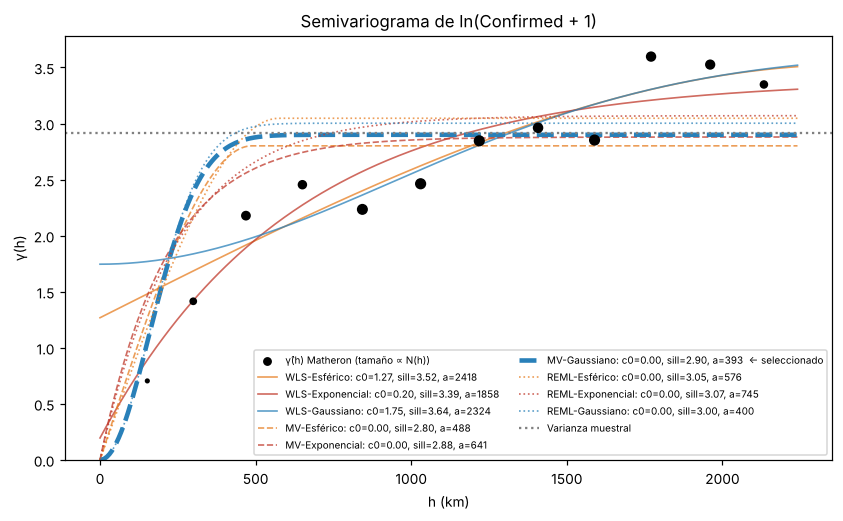

In [17]:
def kriging_ordinario(xy_obs, z_obs, destino, vfun):
    """Kriging Ordinario en forma de semivariograma. Devuelve predicción, varianza y pesos."""
    n = len(z_obs)
    A = np.ones((n + 1, n + 1)); A[n, n] = 0.0
    A[:n, :n] = vfun(cdist(xy_obs, xy_obs))
    B = np.vstack([vfun(cdist(xy_obs, destino)), np.ones(len(destino))])
    W = np.linalg.solve(A, B)
    pred = W[:n].T @ z_obs
    var = (W * B).sum(0)                 # σ²_OK = Σ λ_i γ(s_i, s0) + μ
    return pred, np.maximum(var, 0), W

def loo_ok(xy_obs, z_obs, vfun):
    pred, var = np.empty(len(z_obs)), np.empty(len(z_obs))
    for k in range(len(z_obs)):
        m = np.arange(len(z_obs)) != k
        p_, v_, _ = kriging_ordinario(xy_obs[m], z_obs[m], xy_obs[[k]], vfun)
        pred[k], var[k] = p_[0], v_[0]
    return pred, var

def vfun_desde(fila):
    return lambda h: gamma_modelo(h, fila["Nugget c0"], fila["Meseta parcial c"], fila["Alcance a (km)"], fila["Modelo"])

cv_rmse, cv_rmss, conds = [], [], []
for _, fila in ajustes_z1.iterrows():
    vf = vfun_desde(fila)
    p_, v_ = loo_ok(xy, z1, vf)
    met = metricas(z1, p_, v_)
    cv_rmse.append(met["RMSE"]); cv_rmss.append(met["RMSS"])
    A_ = np.ones((len(z1) + 1, len(z1) + 1)); A_[-1, -1] = 0; A_[:-1, :-1] = vf(D_obs)
    conds.append(np.linalg.cond(A_))
ajustes_z1["RMSE LOO"], ajustes_z1["RMSS LOO"], ajustes_z1["cond(A)"] = cv_rmse, cv_rmss, conds
display(ajustes_z1.round(3))
ajustes_z1.round(4).to_csv(RES / "f3_variograma_confirmed_modelos.csv", index=False)

# Regla: entre los ajustes numéricamente estables (cond(A) < 1e6) y con |RMSS − 1| < 0,1, el de menor RMSE LOO
estables = ajustes_z1[(ajustes_z1["cond(A)"] < 1e6) & ((ajustes_z1["RMSS LOO"] - 1).abs() < 0.1)]
mejor_fila = estables.loc[estables["RMSE LOO"].idxmin()]
MODELO, METODO = mejor_fila["Modelo"], mejor_fila["Método"]
par_z1 = mejor_fila
print(f"Seleccionado: modelo {MODELO}, estimado por {METODO} "
      f"(c0 = {par_z1['Nugget c0']:.3f}, c = {par_z1['Meseta parcial c']:.3f}, a = {par_z1['Alcance a (km)']:.0f} km)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(h1, g1, s=n1 / 2, color="k", zorder=3, label="γ̂(h) Matheron (tamaño ∝ N(h))")
hh = np.linspace(0, MAXLAG, 300)
colores_m = {"Esférico": "#e67e22", "Exponencial": "#c0392b", "Gaussiano": "#2980b9"}
estilos = {"WLS": "-", "MV": "--", "REML": ":"}
for _, f in ajustes_z1.iterrows():
    sel = (f["Modelo"] == MODELO) and (f["Método"] == METODO)
    ax.plot(hh, f["Nugget c0"] + f["Meseta parcial c"] * estructura(hh, f["Alcance a (km)"], f["Modelo"]),
            color=colores_m[f["Modelo"]], ls=estilos[f["Método"]], lw=3 if sel else 1.1, alpha=1 if sel else 0.75,
            label=f"{f['Método']}-{f['Modelo']}: c0={f['Nugget c0']:.2f}, sill={f['Sill c0+c']:.2f}, a={f['Alcance a (km)']:.0f}"
                  + ("  ← seleccionado" if sel else ""))
ax.axhline(z1.var(ddof=1), color="grey", ls=":", label="Varianza muestral")
ax.set(xlabel="h (km)", ylabel="γ(h)", title="Semivariograma de ln(Confirmed + 1)", ylim=(0, None))
ax.legend(fontsize=6.5, ncol=2, loc="lower right")
guardar_fig(fig, "f3_semivariograma_confirmed")
plt.show()

**Análisis de resultados.**
1. **WLS vs verosimilitud.** Los ajustes WLS reproducen el semivariograma empírico a gran escala (alcances de 1858 a 2418 km, pepita del 6 al 48 %), pero el empírico sigue creciendo más allá de 1500 km, indicio de variación de gran escala (gradiente oeste-este de la primera ola) más que de una meseta estacionaria. MV y REML, que usan la matriz de covarianza completa y no dependen de la agrupación en *lags*, estiman **pepita ≈ 0** y alcances de 393 a 745 km.
2. **Selección.** La regla es: entre los ajustes con matriz de Kriging bien condicionada ($\kappa(A)<10^6$) y varianza calibrada ($|\text{RMSS}-1|<0{,}1$), el de menor RMSE LOO. Por validación cruzada, los ajustes por verosimilitud dominan: RMSE ≈ 1,58 a 1,67 y RMSS ≈ 1,01 a 1,02, frente a RMSE ≈ 1,75 a 1,82 y RMSS ≈ 1,17 a 1,28 de WLS, que **subestiman la varianza**. Esto concuerda con Stein (1999): la calidad de la interpolación depende sobre todo del comportamiento de $\gamma$ cerca del origen, que la verosimilitud estima mejor. Se selecciona **Gaussiano (MV): $c_0\approx0$, $c\approx2{,}90$, $a\approx393$ km**.
3. **¿Por qué gaussiano y no exponencial?** A soporte puntual, la transmisión epidémica debería mostrar un comportamiento lineal en el origen. Pero cada dato es un **agregado nacional**, es decir, un valor **regularizado** sobre un bloque de cientos de miles de km². La regularización suaviza el semivariograma cerca del origen y lo vuelve parabólico (Journel y Huijbregts, 1978), que es la firma del modelo gaussiano. La diferencia con el esférico MV es mínima (RMSE 1,583 vs 1,601), por lo que la conclusión es robusta al modelo.
4. **Lectura epidemiológica.** Pepita ≈ 0 indica dependencia espacial **fuerte** una vez homogeneizado el soporte. El alcance práctico de ≈ 390 km equivale a la escala de **países contiguos**: más allá de esa distancia, la carga epidémica de un país no aporta información sobre la de otro.

## 3.2 Kriging Ordinario y Cokriging Ordinario

### a) Sistema del Kriging Ordinario para *Deaths*
Sea $Z_2(s)=\ln(\text{Deaths}+1)$ con media constante desconocida $\mu$. El predictor es $\hat Z_2(s_0)=\sum_{i=1}^n\lambda_i Z_2(s_i)$.

* **Insesgadez:** $\mathbb{E}[\hat Z_2(s_0)-Z_2(s_0)]=\mu\left(\sum_i\lambda_i-1\right)=0\ \Rightarrow\ \sum_{i=1}^n\lambda_i=1$.
* **Varianza del error** (en términos de $\gamma$, válida bajo hipótesis intrínseca):
$$\sigma_E^2=\operatorname{Var}[\hat Z_2(s_0)-Z_2(s_0)]=2\sum_i\lambda_i\gamma(s_i,s_0)-\sum_i\sum_j\lambda_i\lambda_j\gamma(s_i,s_j).$$
* **Minimización con restricción** (Lagrangiano $\mathcal{L}=\sigma_E^2+2\mu_L(\sum_i\lambda_i-1)$), derivando respecto de $\lambda_i$ y $\mu_L$:
$$\sum_{j=1}^n\lambda_j\gamma(s_i,s_j)+\mu_L=\gamma(s_i,s_0),\quad i=1,\dots,n;\qquad \sum_{j=1}^n\lambda_j=1.$$
En forma matricial:
$$\begin{pmatrix}\gamma_{11}&\cdots&\gamma_{1n}&1\\\vdots&\ddots&\vdots&\vdots\\\gamma_{n1}&\cdots&\gamma_{nn}&1\\1&\cdots&1&0\end{pmatrix}
\begin{pmatrix}\lambda_1\\\vdots\\\lambda_n\\\mu_L\end{pmatrix}=
\begin{pmatrix}\gamma_{10}\\\vdots\\\gamma_{n0}\\1\end{pmatrix},\qquad
\sigma^2_{OK}(s_0)=\sum_{i=1}^n\lambda_i\gamma_{i0}+\mu_L.$$

El semivariograma de $Z_2$ se ajusta con el mismo procedimiento; la implementación propia se verifica contra `pykrige`.

,Método,Modelo,Nugget c0,Meseta parcial c,Sill c0+c,Alcance a (km),c0/(c0+c) (%),RMSE LOO,RMSS LOO
0,WLS,Esférico,1.903,5.571,7.474,3919.342,25.466,2.174,1.193
1,WLS,Exponencial,1.613,7.617,9.230,7763.115,17.473,2.209,1.219
2,WLS,Gaussiano,2.672,4.189,6.861,2937.971,38.946,2.120,1.153
3,MV,Esférico,0.000,4.559,4.559,446.819,0.002,2.065,1.005
4,MV,Exponencial,0.000,4.788,4.788,688.909,0.002,2.123,1.029
5,MV,Gaussiano,0.000,4.851,4.851,400.261,0.002,2.067,1.024
6,REML,Esférico,3.248,5.308,8.556,8965.135,37.958,2.058,1.014
7,REML,Exponencial,3.098,3.921,7.018,8965.135,44.135,2.074,1.017
8,REML,Gaussiano,0.000,5.040,5.040,409.247,0.002,2.074,1.017


Seleccionado para ln(Deaths+1): Esférico (REML), c0 = 3.248, c = 5.308, a = 8965 km
Máx. |diferencia| con pykrige (predicción): 0.0 (pykrige usa el alcance efectivo; diferencias pequeñas son esperables en exponencial/gaussiano)


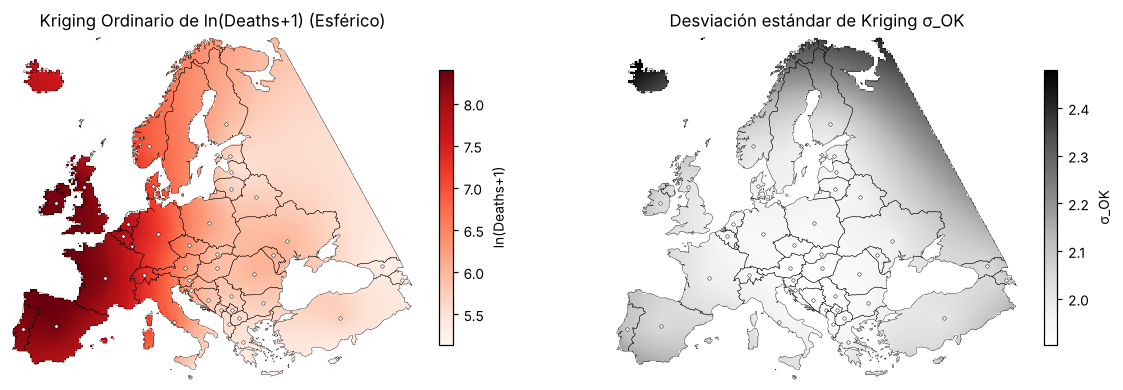

In [18]:
h2, g2, n2 = variograma_empirico(xy, z2, maxlag=MAXLAG)
ajustes_z2 = pd.concat([pd.DataFrame([ajustar_variograma(h2, g2, n2, m) for m in MODELOS]).assign(Método="WLS"),
                        pd.DataFrame([ajustar_mv(z2, m, reml) for reml in (False, True) for m in MODELOS])],
                       ignore_index=True)
cv2 = [metricas(z2, *loo_ok(xy, z2, vfun_desde(f))) for _, f in ajustes_z2.iterrows()]
ajustes_z2["RMSE LOO"] = [c["RMSE"] for c in cv2]
ajustes_z2["RMSS LOO"] = [c["RMSS"] for c in cv2]
cols_v = ["Método", "Modelo", "Nugget c0", "Meseta parcial c", "Sill c0+c", "Alcance a (km)", "c0/(c0+c) (%)", "RMSE LOO", "RMSS LOO"]
display(ajustes_z2[cols_v].round(3))
ajustes_z2[cols_v].round(4).to_csv(RES / "f3_variograma_deaths_modelos.csv", index=False)
estables2 = ajustes_z2[(ajustes_z2["RMSS LOO"] - 1).abs() < 0.1]
estables2 = estables2 if len(estables2) else ajustes_z2
par_z2 = estables2.loc[estables2["RMSE LOO"].idxmin()]
MODELO_Z2 = par_z2["Modelo"]
vfun_z2 = vfun_desde(par_z2)
print(f"Seleccionado para ln(Deaths+1): {MODELO_Z2} ({par_z2['Método']}), c0 = {par_z2['Nugget c0']:.3f}, c = {par_z2['Meseta parcial c']:.3f}, a = {par_z2['Alcance a (km)']:.0f} km")

# Kriging Ordinario de ln(Deaths+1) sobre la grilla
z2_ok, z2_ok_var, _ = kriging_ordinario(xy, z2, nodos, vfun_z2)

# Verificación con pykrige (mismo modelo y parámetros)
mapa_pk = {"Esférico": "spherical", "Exponencial": "exponential", "Gaussiano": "gaussian"}
ok_pk = OrdinaryKriging(xy[:, 0], xy[:, 1], z2, variogram_model=mapa_pk[MODELO_Z2],
                        variogram_parameters={"sill": par_z2["Sill c0+c"], "range": par_z2["Alcance a (km)"],
                                              "nugget": par_z2["Nugget c0"]}, exact_values=True)
muestra = nodos[::50]
pk_pred, pk_var = ok_pk.execute("points", muestra[:, 0], muestra[:, 1])
print("Máx. |diferencia| con pykrige (predicción):", np.abs(np.asarray(pk_pred) - z2_ok[::50]).max().round(4),
      "(pykrige usa el alcance efectivo; diferencias pequeñas son esperables en exponencial/gaussiano)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mapa(axes[0], z2_ok, f"Kriging Ordinario de ln(Deaths+1) ({MODELO_Z2})", "Reds", "ln(Deaths+1)")
mapa(axes[1], np.sqrt(z2_ok_var), "Desviación estándar de Kriging σ_OK", "Greys", "σ_OK")
guardar_fig(fig, "f3_ok_deaths")
plt.show()

**Verificación de tendencia: Kriging Universal (UK).** Si el semivariograma de $\ln(\text{Deaths}+1)$ no alcanza una meseta dentro del dominio (alcance estimado mayor que la extensión del área), puede existir una **deriva** $m(s)=\beta_0+\beta_1x+\beta_2y$ (gradiente oeste-este de la mortalidad en la primera ola). El UK añade las restricciones de insesgadez $\sum_i\lambda_i f_k(s_i)=f_k(s_0)$:
$$\begin{pmatrix}\Gamma&\mathbf F\\\mathbf F^\top&\mathbf 0\end{pmatrix}\begin{pmatrix}\boldsymbol\lambda\\\boldsymbol\mu\end{pmatrix}=\begin{pmatrix}\boldsymbol\gamma_0\\\mathbf f_0\end{pmatrix},\qquad \mathbf F=[\mathbf 1,\ \mathbf x,\ \mathbf y],$$
con $\Gamma$ el semivariograma de los **residuos** de la deriva. Se compara con OK por validación cruzada.

In [19]:
def kriging_universal(xy_obs, z_obs, destino, vfun):
    deriva = lambda p: np.column_stack([np.ones(len(p)), p[:, 0] / 1000, p[:, 1] / 1000])
    n, Fo = len(z_obs), deriva(xy_obs)
    q = Fo.shape[1]
    A = np.zeros((n + q, n + q))
    A[:n, :n] = vfun(cdist(xy_obs, xy_obs))
    A[:n, n:], A[n:, :n] = Fo, Fo.T
    B = np.vstack([vfun(cdist(xy_obs, destino)), deriva(destino).T])
    W = np.linalg.solve(A, B)
    return W[:n].T @ z_obs, np.maximum((W * B).sum(0), 0)

X_der = np.column_stack([np.ones(len(z2)), xy / 1000])
beta, *_ = np.linalg.lstsq(X_der, z2, rcond=None)
resid = z2 - X_der @ beta
ols = sm.OLS(z2, X_der).fit()
print(f"Deriva lineal ln(Deaths+1) ~ x + y: R² = {ols.rsquared:.3f}; p-valores (x, y) = {ols.pvalues[1]:.4f}, {ols.pvalues[2]:.4f}")

hr, gr, nr = variograma_empirico(xy, resid, maxlag=MAXLAG)
ajustes_res = pd.DataFrame([ajustar_variograma(hr, gr, nr, m) for m in MODELOS])
filas_uk = []
for _, fila in ajustes_res.iterrows():
    vf = vfun_desde(fila)
    pu = np.empty(len(z2)); vu = np.empty(len(z2))
    for k in range(len(z2)):
        m = np.arange(len(z2)) != k
        a_, b_ = kriging_universal(xy[m], z2[m], xy[[k]], vf)
        pu[k], vu[k] = a_[0], b_[0]
    filas_uk.append({"Estimador": f"UK ({fila['Modelo']})", **metricas(z2, pu, vu)})
p_ok2, v_ok2 = loo_ok(xy, z2, vfun_z2)
comp_uk = pd.DataFrame([{"Estimador": f"OK ({MODELO_Z2}, {par_z2['Método']})", **metricas(z2, p_ok2, v_ok2)}] + filas_uk)
display(ajustes_res.round(3))
display(comp_uk.round(4))
comp_uk.round(4).to_csv(RES / "f3_ok_vs_uk_deaths.csv", index=False)

Deriva lineal ln(Deaths+1) ~ x + y: R² = 0.217; p-valores (x, y) = 0.0027, 0.7790


,Modelo,Nugget c0,Meseta parcial c,Sill c0+c,Alcance a (km),c0/(c0+c) (%),SSE ponderado
0,Esférico,1.125,2.786,3.911,1019.763,28.770,175.520
1,Exponencial,1.102,3.113,4.215,1702.625,26.143,144.336
2,Gaussiano,1.567,2.354,3.921,883.819,39.960,169.382


,Estimador,ME,MAE,RMSE,"r(obs,pred)",MSE estandarizado,RMSS
0,"OK (Esférico, REML)",0.0035,1.6746,2.0583,0.3027,0.0006,1.0141
1,UK (Esférico),-0.0403,1.8783,2.3071,0.1878,-0.0148,1.2695
2,UK (Exponencial),-0.0166,1.8089,2.2434,0.2299,-0.0077,1.2323
3,UK (Gaussiano),-0.0391,1.8921,2.3085,0.1865,-0.0145,1.2755


**Análisis de resultados.** Para $\ln(\text{Deaths}+1)$ el mejor ajuste por validación cruzada es **Esférico (REML)** con pepita ≈ 3,25 y alcance en el límite superior (≈ 8965 km): el semivariograma **no alcanza meseta dentro del dominio**, típico de una deriva. La regresión lineal en coordenadas confirma un gradiente **oeste-este** significativo ($p_x\approx0{,}003$, $R^2\approx0{,}22$), coherente con la mayor mortalidad de Europa occidental en la primera ola. Sin embargo, el **Kriging Universal no mejora** la predicción (RMSE 2,24 a 2,31 frente a 2,06 del OK; RMSS 1,23 a 1,28 frente a 1,01): el OK re-estima la media localmente en cada vecindad y absorbe la deriva sin el costo de estimar $\beta$ con 42 datos. Se mantiene el **OK** para el mapa de fallecidos. Su desviación estándar es mínima junto a los sitios y crece hacia Rusia europea, el norte de Escandinavia y Anatolia, donde no hay observaciones.

### b) Cokriging Ordinario (OCK)
Primaria $Z_1(s)=\ln(\text{Confirmed}+1)$, secundaria $Z_2(s)=\ln(\text{Deaths}+1)$, ambas observadas en los mismos $n$ sitios (muestreo **isotópico**, variable secundaria co-localizada). El predictor:
$$\hat Z_1(s_0)=\sum_{i=1}^{n}\lambda_{1i}Z_1(s_i)+\sum_{j=1}^{n}\lambda_{2j}Z_2(s_j).$$

**Insesgadez:** $\sum_i\lambda_{1i}=1$ y $\sum_j\lambda_{2j}=0$.
**Sistema** (con multiplicadores $\mu_1,\mu_2$):
$$\begin{pmatrix}\Gamma_{11}&\Gamma_{12}&\mathbf 1&\mathbf 0\\\Gamma_{21}&\Gamma_{22}&\mathbf 0&\mathbf 1\\\mathbf 1^\top&\mathbf 0^\top&0&0\\\mathbf 0^\top&\mathbf 1^\top&0&0\end{pmatrix}
\begin{pmatrix}\boldsymbol\lambda_1\\\boldsymbol\lambda_2\\\mu_1\\\mu_2\end{pmatrix}=
\begin{pmatrix}\boldsymbol\gamma_{11}(s_0)\\\boldsymbol\gamma_{21}(s_0)\\1\\0\end{pmatrix},\qquad
\sigma^2_{OCK}(s_0)=\boldsymbol\lambda_1^\top\boldsymbol\gamma_{11}(s_0)+\boldsymbol\lambda_2^\top\boldsymbol\gamma_{21}(s_0)+\mu_1.$$

**Semivariograma cruzado.**
$$\gamma_{12}(h)=\tfrac12\,\mathbb{E}\big[(Z_1(s+h)-Z_1(s))(Z_2(s+h)-Z_2(s))\big],\qquad
\hat\gamma_{12}(h)=\frac{1}{2|N(h)|}\sum_{N(h)}[z_1(s_i)-z_1(s_j)][z_2(s_i)-z_2(s_j)].$$
Para que $\sigma^2_{OCK}\ge0$ se usa el **Modelo Lineal de Corregionalización (LMC)**:
$$\boldsymbol\Gamma(h)=\begin{pmatrix}\gamma_{11}&\gamma_{12}\\\gamma_{21}&\gamma_{22}\end{pmatrix}=\mathbf B_0\,g_0(h)+\mathbf B_1\,g_1(h),$$
con $g_0$ el efecto pepita, $g_1$ la estructura seleccionada (meseta unitaria y alcance común $a$) y $\mathbf B_0,\mathbf B_1$ matrices de corregionalización **semidefinidas positivas** (condición suficiente de admisibilidad). Para que el LMC sea coherente con 3.1 se fijan la estructura y el alcance $a$ del semivariograma seleccionado para Confirmed: los coeficientes directos ($b_{11}$, $b_{22}$) se estiman por el mismo método de verosimilitud con $a$ fijo y los cruzados como $b^{(k)}_{12}=\rho\sqrt{b^{(k)}_{11}b^{(k)}_{22}}$, con $\rho$ la correlación co-localizada entre $Z_1$ y $Z_2$. Como $|\rho|<1$, se cumple la desigualdad de Cauchy-Schwarz $|b^{(k)}_{12}|\le\sqrt{b^{(k)}_{11}b^{(k)}_{22}}$, que en el caso bivariado equivale a $\mathbf B_k\succeq 0$ (Goulard y Voltz, 1992; Wackernagel, 2003). El ajuste WLS libre de $\hat\gamma_{12}$ se reporta como contraste: si excede la cota, el LMC dejaría de ser admisible.

*Observación teórica:* si $\mathbf B_0\propto\mathbf B_1$ (corregionalización intrínseca) y el muestreo es isotópico, el cokriging coincide con el kriging; la ganancia del OCK depende de que la estructura cruzada difiera de la directa.

b12 por WLS libre: nugget -1.726, meseta 5.104 (cota de Cauchy-Schwarz 3.731); ρ co-localizada = 0.957 → b12 = 3.570


,Componente,Nugget (B0),Meseta parcial (B1),Alcance a (km),Modelo
0,γ11 Confirmed,0.0001,2.8994,392.9713,Gaussiano
1,γ12 cruzado,0.0001,3.5702,392.9713,Gaussiano
2,γ22 Deaths,0.0001,4.8003,392.9713,Gaussiano


Autovalores B0: [0.     0.0002] | B1: [0.1553 7.5444] (≥ 0: LMC admisible)
Correlación estructural (B1): 0.957; (B0): 0.957


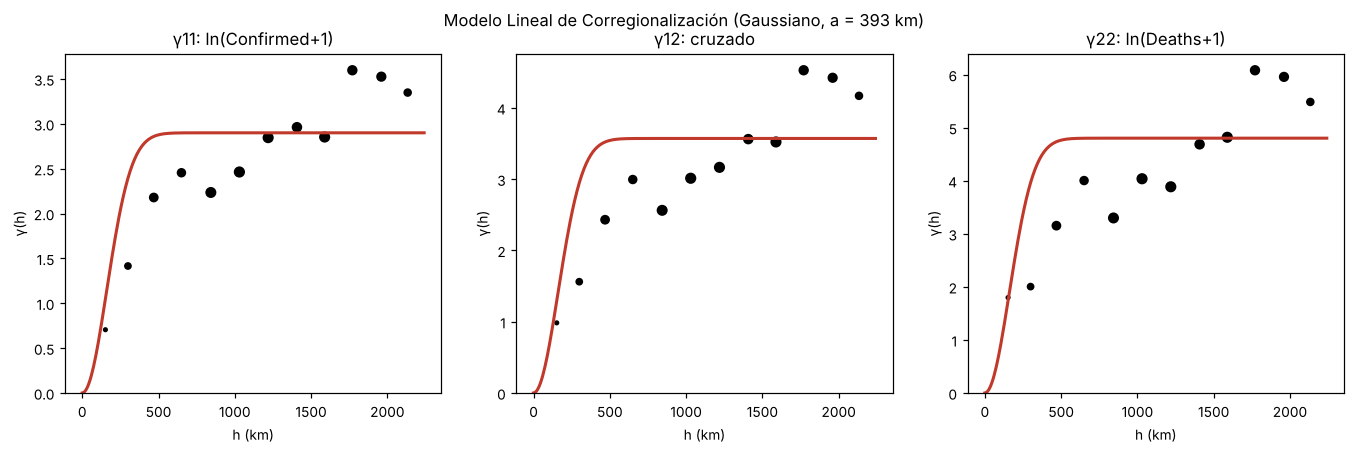

In [20]:
h12, g12, n12 = variograma_empirico(xy, z1, z2, maxlag=MAXLAG)
empiricos = {(0, 0): (h1, g1, n1), (1, 1): (h2, g2, n2), (0, 1): (h12, g12, n12)}
# LMC coherente con 3.1: estructura y alcance del semivariograma seleccionado para Confirmed.
# Directos (γ11, γ22): (c0, c) por el mismo método de 3.1 con alcance fijo.
a_lmc = par_z1["Alcance a (km)"]

def ajustar_mv_alcance_fijo(z, modelo, a, reml):
    v = z.var(ddof=1)
    f = lambda pl: neg_loglik(np.r_[pl, np.log(a)], modelo, z, reml)
    sol = min((minimize(f, np.log([fr * v, (1 - fr) * v]), method="L-BFGS-B",
                        bounds=[(np.log(1e-4), np.log(3 * v))] * 2) for fr in (0.1, 0.5, 0.9)), key=lambda r: r.fun)
    return np.exp(sol.x)

reml_flag = METODO == "REML"
c0_11, c_11 = par_z1["Nugget c0"], par_z1["Meseta parcial c"]
c0_22, c_22 = ajustar_mv_alcance_fijo(z2, MODELO, a_lmc, reml_flag)
# Coeficiente cruzado: correlación estructural ρ estimada por la correlación co-localizada (estimador de momentos
# de C12(0)/√(C11(0)C22(0))); la estimación WLS libre sobre γ̂12 se reporta como contraste.
X12 = np.column_stack([np.ones_like(h12), estructura(h12, a_lmc, MODELO)]) * np.sqrt(n12)[:, None]
b0_wls, b1_wls = np.linalg.lstsq(X12, g12 * np.sqrt(n12), rcond=None)[0]
rho = np.corrcoef(z1, z2)[0, 1]
b0_12, b1_12 = rho * np.sqrt(c0_11 * c0_22), rho * np.sqrt(c_11 * c_22)
print(f"b12 por WLS libre: nugget {b0_wls:.3f}, meseta {b1_wls:.3f} (cota de Cauchy-Schwarz {np.sqrt(c_11 * c_22):.3f}); "
      f"ρ co-localizada = {rho:.3f} → b12 = {b1_12:.3f}")
B0 = np.array([[c0_11, b0_12], [b0_12, c0_22]])
B1 = np.array([[c_11, b1_12], [b1_12, c_22]])

def gamma_lmc(p, q, h):
    h = np.asarray(h, float)
    return np.where(h > 0, B0[p, q] + B1[p, q] * estructura(h, a_lmc, MODELO), 0.0)

lmc_tabla = pd.DataFrame({
    "Componente": ["γ11 Confirmed", "γ12 cruzado", "γ22 Deaths"],
    "Nugget (B0)": [B0[0, 0], B0[0, 1], B0[1, 1]],
    "Meseta parcial (B1)": [B1[0, 0], B1[0, 1], B1[1, 1]],
})
lmc_tabla["Alcance a (km)"] = a_lmc
lmc_tabla["Modelo"] = MODELO
display(lmc_tabla.round(4))
print("Autovalores B0:", np.linalg.eigvalsh(B0).round(4), "| B1:", np.linalg.eigvalsh(B1).round(4), "(≥ 0: LMC admisible)")
print(f"Correlación estructural (B1): {B1[0, 1] / np.sqrt(B1[0, 0] * B1[1, 1]):.3f}; "
      f"(B0): {B0[0, 1] / np.sqrt(B0[0, 0] * B0[1, 1]) if B0[0, 0] * B0[1, 1] > 0 else float('nan'):.3f}")
lmc_tabla.round(4).to_csv(RES / "f3_lmc.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (p, q), t in zip(axes, [(0, 0), (0, 1), (1, 1)], ["γ11: ln(Confirmed+1)", "γ12: cruzado", "γ22: ln(Deaths+1)"]):
    h, g, n = empiricos[(p, q)]
    ax.scatter(h, g, s=n / 2, color="k")
    ax.plot(hh, gamma_lmc(p, q, np.maximum(hh, 1e-6)), color="#c0392b", lw=2)
    ax.set(title=t, xlabel="h (km)", ylabel="γ(h)", ylim=(0, None))
fig.suptitle(f"Modelo Lineal de Corregionalización ({MODELO}, a = {a_lmc:.0f} km)")
guardar_fig(fig, "f3_lmc_variogramas")
plt.show()

**Análisis de resultados.** El ajuste WLS libre del semivariograma cruzado da una meseta de ≈ 5,10, **mayor que la cota de Cauchy-Schwarz** (≈ 3,73): usado tal cual, el LMC no sería admisible y podría producir varianzas negativas. Con $\rho\approx0{,}957$ el LMC es admisible (autovalores ≥ 0). Como $\mathbf B_0\approx\mathbf 0$ y $\mathbf B_1$ tiene correlación estructural igual a la co-localizada, el modelo resultante es de **corregionalización intrínseca**: $\boldsymbol\Gamma(h)=\mathbf V\,\gamma_u(h)$. Bajo esta estructura con muestreo isotópico, la teoría predice **autokrigeabilidad** (Wackernagel, 2003): el OCK asigna peso nulo efectivo a la secundaria y coincide con el OK.

Varianza media de predicción: OK = 2.1969, OCK = 2.1969 (reducción -0.0 %)
Suma de pesos primarios (debe ser 1): 1.0000; secundarios (debe ser 0): -6.61e-19


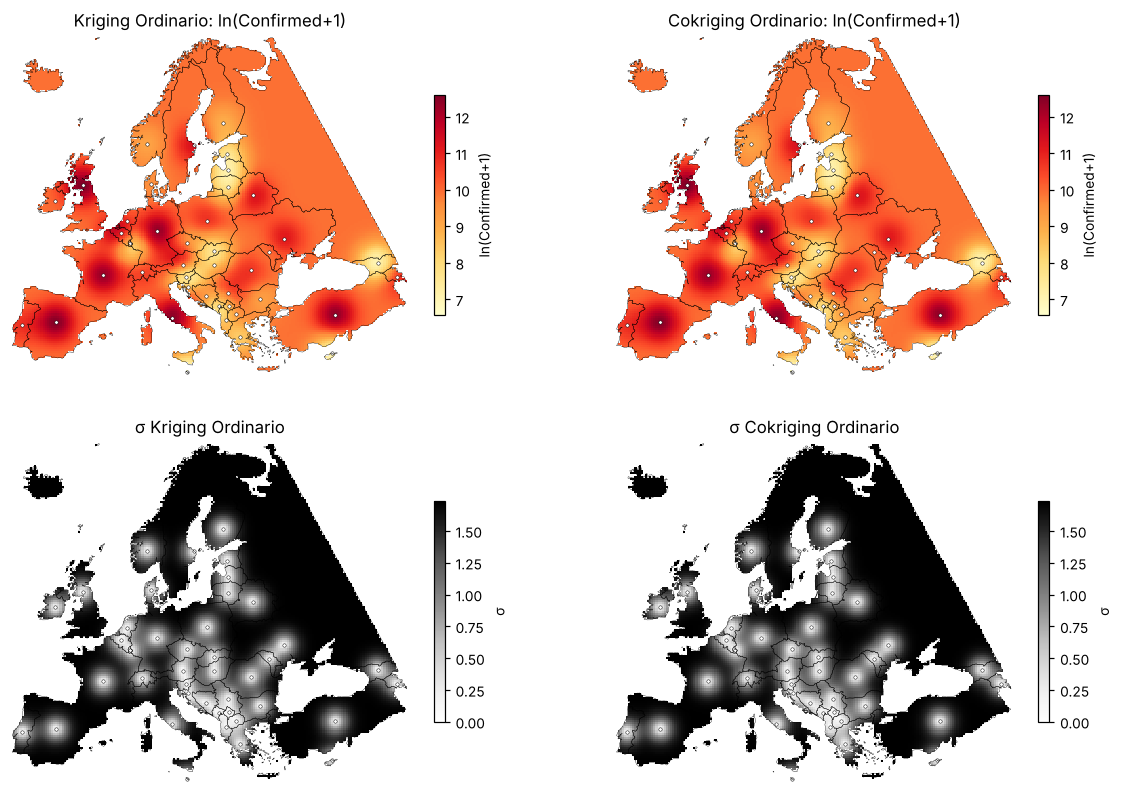

In [21]:
def cokriging_ordinario(xy1, v1, xy2, v2, destino):
    """Cokriging Ordinario con LMC; admite muestreo isotópico o heterotópico."""
    n1, n2 = len(v1), len(v2)
    N = n1 + n2 + 2
    A = np.zeros((N, N))
    A[:n1, :n1] = gamma_lmc(0, 0, cdist(xy1, xy1))
    A[:n1, n1:n1 + n2] = gamma_lmc(0, 1, cdist(xy1, xy2))
    A[n1:n1 + n2, :n1] = A[:n1, n1:n1 + n2].T
    A[n1:n1 + n2, n1:n1 + n2] = gamma_lmc(1, 1, cdist(xy2, xy2))
    A[:n1, N - 2] = A[N - 2, :n1] = 1
    A[n1:n1 + n2, N - 1] = A[N - 1, n1:n1 + n2] = 1
    A[:n1 + n2, :n1 + n2] -= 1e-6 * np.eye(n1 + n2)   # regularización numérica mínima
    B = np.zeros((N, len(destino)))
    B[:n1] = gamma_lmc(0, 0, cdist(xy1, destino))
    B[n1:n1 + n2] = gamma_lmc(1, 0, cdist(xy2, destino))
    B[N - 2] = 1
    W = np.linalg.solve(A, B)
    pred = W[:n1].T @ v1 + W[n1:n1 + n2].T @ v2
    var = (W * B).sum(0)
    return pred, np.maximum(var, 0), W

vfun_z1 = vfun_desde(par_z1)                     # OK de Confirmed con el semivariograma seleccionado en 3.1
z1_ok, z1_ok_var, _ = kriging_ordinario(xy, z1, nodos, vfun_z1)
z1_ock, z1_ock_var, W_ock = cokriging_ordinario(xy, z1, xy, z2, nodos)

reduccion_var = 100 * (1 - z1_ock_var.mean() / z1_ok_var.mean())
print(f"Varianza media de predicción: OK = {z1_ok_var.mean():.4f}, OCK = {z1_ock_var.mean():.4f} "
      f"(reducción {reduccion_var:.1f} %)")
print(f"Suma de pesos primarios (debe ser 1): {W_ock[:len(z1)].sum(0).mean():.4f}; "
      f"secundarios (debe ser 0): {W_ock[len(z1):2 * len(z1)].sum(0).mean():.2e}")

fig, axes = plt.subplots(2, 2, figsize=(13, 8.8))
vmin, vmax = min(z1_ok.min(), z1_ock.min()), max(z1_ok.max(), z1_ock.max())
smax = np.sqrt(max(z1_ok_var.max(), z1_ock_var.max()))
mapa(axes[0, 0], z1_ok, "Kriging Ordinario: ln(Confirmed+1)", "YlOrRd", "ln(Confirmed+1)", vmin, vmax)
mapa(axes[0, 1], z1_ock, "Cokriging Ordinario: ln(Confirmed+1)", "YlOrRd", "ln(Confirmed+1)", vmin, vmax)
mapa(axes[1, 0], np.sqrt(z1_ok_var), "σ Kriging Ordinario", "Greys", "σ", 0, smax)
mapa(axes[1, 1], np.sqrt(z1_ock_var), "σ Cokriging Ordinario", "Greys", "σ", 0, smax)
guardar_fig(fig, "f3_ok_vs_ock_confirmed")
plt.show()

**Análisis de resultados.** Los mapas de OK y OCK son idénticos y la varianza media también (≈ 2,20), lo que **verifica numéricamente la autokrigeabilidad**: cuando Deaths se observa en los mismos sitios que Confirmed y ambas comparten la misma estructura espacial, Deaths no aporta información adicional para predecir **en lugares sin datos**. La superficie muestra el núcleo de alta carga en el corredor Reino Unido-Benelux-Francia-Península Ibérica y focos en Alemania, Italia, Suecia, Bielorrusia, Ucrania, Rumania y Turquía. Los máximos coinciden con los centroides de los países más poblados porque Confirmed es un **conteo total**: la superficie mezcla riesgo con tamaño poblacional. Por eso la Fase 4 complementa con la incidencia por 100 000 habitantes. La desviación estándar se anula en los sitios (pepita ≈ 0, interpolador exacto) y alcanza la meseta ($\sigma\approx1{,}7$) a más de ≈ 400 km de cualquier sitio.

### c) Validación cruzada: RMSE y RMSS
En *leave-one-out* se elimina cada sitio $s_k$, se predice con los $n-1$ restantes y se calcula el error $e_k=\hat Z(s_k)-Z(s_k)$ y su versión estandarizada $e_k/\sigma(s_k)$:
$$\text{RMSE}=\sqrt{\tfrac1n\textstyle\sum_k e_k^2},\qquad
\text{RMSS}=\sqrt{\tfrac1n\textstyle\sum_k \left(e_k/\sigma(s_k)\right)^2}.$$
* **RMSE** mide la **exactitud**: se prefiere el menor.
* **RMSS** mide la **calibración de la incertidumbre**: debe ser ≈ 1. RMSS > 1 indica que el modelo **subestima** su varianza (mapas de incertidumbre optimistas); RMSS < 1, que la **sobrestima**.
* El error medio (ME) y el error medio estandarizado deben ser ≈ 0 (insesgadez).

**Regla de decisión:** se elige el estimador con menor RMSE siempre que su RMSS esté razonablemente cerca de 1; si los RMSE son similares, se prefiere el de RMSS más cercano a 1.

Se evalúan tres escenarios: (i) OK; (ii) OCK isotópico, donde en $s_k$ se eliminan ambas variables (escenario de predicción en lugares sin información); (iii) OCK con secundaria co-localizada, donde en $s_k$ se conoce Deaths pero no Confirmed (escenario de subregistro de casos con registro de defunciones disponible).

,Estimador,ME,MAE,RMSE,"r(obs,pred)",MSE estandarizado,RMSS
0,IDW (p = 1.5),-0.1508,1.3528,1.6552,0.2183,NaN,NaN
0,OK,-0.1074,1.2759,1.5826,0.3596,-0.0432,1.0192
1,OCK isotópico,-0.1074,1.2759,1.5826,0.3596,-0.0432,1.0192
2,OCK co-localizado,-0.0232,0.3997,0.5413,0.9478,-0.0404,1.4120


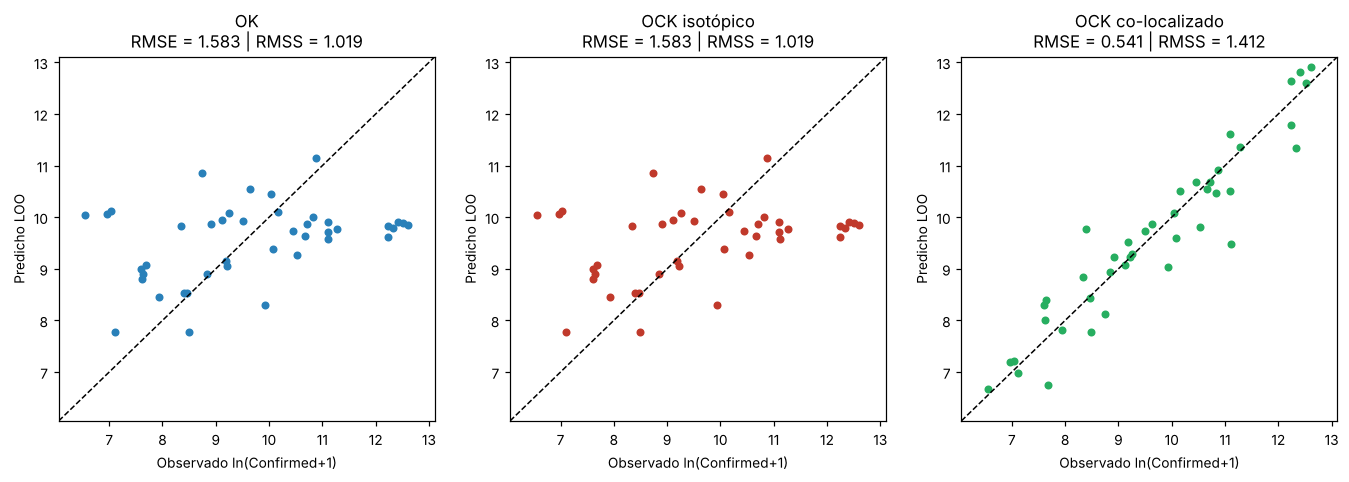

In [22]:
n = len(z1)
cv = {k: (np.empty(n), np.empty(n)) for k in ["OK", "OCK isotópico", "OCK co-localizado"]}
for k in range(n):
    m = np.arange(n) != k
    p_, v_, _ = kriging_ordinario(xy[m], z1[m], xy[[k]], vfun_z1)
    cv["OK"][0][k], cv["OK"][1][k] = p_[0], v_[0]
    p_, v_, _ = cokriging_ordinario(xy[m], z1[m], xy[m], z2[m], xy[[k]])
    cv["OCK isotópico"][0][k], cv["OCK isotópico"][1][k] = p_[0], v_[0]
    p_, v_, _ = cokriging_ordinario(xy[m], z1[m], xy, z2, xy[[k]])
    cv["OCK co-localizado"][0][k], cv["OCK co-localizado"][1][k] = p_[0], v_[0]

cv_tabla = pd.DataFrame([{"Estimador": k, **metricas(z1, p_, v_)} for k, (p_, v_) in cv.items()])
cv_tabla = pd.concat([pd.DataFrame([{"Estimador": f"IDW (p = {p_opt:g})", **metricas(z1, loo_idw(p_opt))}]), cv_tabla])
display(cv_tabla.round(4))
cv_tabla.round(4).to_csv(RES / "f3_validacion_cruzada.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
lims = [z1.min() - 0.5, z1.max() + 0.5]
for ax, (k, (p_, v_)), col in zip(axes, cv.items(), ["#2980b9", "#c0392b", "#27ae60"]):
    ax.scatter(z1, p_, color=col, s=18)
    ax.plot(lims, lims, "k--", lw=1)
    met = metricas(z1, p_, v_)
    ax.set(xlim=lims, ylim=lims, xlabel="Observado ln(Confirmed+1)", ylabel="Predicho LOO",
           title=f"{k}\nRMSE = {met['RMSE']:.3f} | RMSS = {met['RMSS']:.3f}")
guardar_fig(fig, "f3_validacion_cruzada")
plt.show()

**Análisis comparativo y selección del estimador.**
* **OK vs IDW:** el OK reduce el RMSE de 1,655 a 1,583 (−4,4 %) y, a diferencia de IDW, entrega una varianza bien calibrada (**RMSS ≈ 1,02**), con sesgo medio cercano a 0.
* **OCK isotópico = OK** (RMSE 1,583, RMSS 1,02), como predice la teoría bajo corregionalización intrínseca.
* **OCK co-localizado:** si en el sitio a predecir se conoce Deaths (por ejemplo, un país con registro de defunciones confiable y subregistro de casos), el RMSE cae a **0,54 (−66 %)** y la correlación observado-predicho sube de 0,36 a 0,95. Su RMSS ≈ 1,41 indica que la varianza del OCK **subestima** el error real en un factor ≈ $1{,}41^2\approx2$; los intervalos deberían ampliarse en consecuencia.

**Elección óptima:** para mapear la superficie continua en zonas sin ninguna observación, OK y OCK son equivalentes y se reporta el **OCK** (incorpora toda la información y nunca es peor que el OK). Cuando la variable secundaria está disponible en el lugar de interés, el **OCK es claramente superior**, siempre que su varianza se recalibre (factor ≈ 2).

---
# Fase 4. Conclusiones y discusión territorial

Se integran (i) la superficie continua de propagación del **Cokriging Ordinario** y su **varianza de error**, (ii) una superficie complementaria de **incidencia acumulada** por Kriging Ordinario (riesgo per cápita, que corrige el efecto tamaño de país) y (iii) la **capacidad sanitaria** de OWID (camas hospitalarias por 1000 hab., población ≥ 65 años). Las predicciones en escala original usan la corrección lognormal $\hat C=\exp(\hat Z+\sigma^2/2)-1$.

In [23]:
# Superficie complementaria: Kriging Ordinario de ln(incidencia por 100 000 hab.)
hi, gi_, ni = variograma_empirico(xy, z_inc, maxlag=MAXLAG)
ajustes_inc = pd.DataFrame([ajustar_variograma(hi, gi_, ni, m) for m in MODELOS])
cvi = []
for _, fila in ajustes_inc.iterrows():
    p_, v_ = loo_ok(xy, z_inc, vfun_desde(fila))
    cvi.append(metricas(z_inc, p_, v_))
ajustes_inc["RMSE LOO"] = [c["RMSE"] for c in cvi]
ajustes_inc["RMSS LOO"] = [c["RMSS"] for c in cvi]
display(ajustes_inc.round(3))
ajustes_inc.round(4).to_csv(RES / "f4_variograma_incidencia.csv", index=False)
par_inc = ajustes_inc.loc[ajustes_inc["RMSE LOO"].idxmin()]
A_INC = par_inc["Alcance a (km)"]
inc_ok, inc_ok_var, _ = kriging_ordinario(xy, z_inc, nodos, vfun_desde(par_inc))
print(f"Incidencia: modelo {par_inc['Modelo']}, c0/(c0+c) = {par_inc['c0/(c0+c) (%)']:.1f} %, alcance práctico a = {A_INC:.0f} km")

,Modelo,Nugget c0,Meseta parcial c,Sill c0+c,Alcance a (km),c0/(c0+c) (%),SSE ponderado,RMSE LOO,RMSS LOO
0,Esférico,0.0,0.805,0.805,460.992,0.0,10.817,0.839,0.984
1,Exponencial,0.0,0.809,0.809,461.579,0.0,11.723,0.859,0.977
2,Gaussiano,0.0,0.807,0.807,395.617,0.0,10.706,0.852,1.116


Incidencia: modelo Esférico, c0/(c0+c) = 0.0 %, alcance práctico a = 461 km


In [24]:
# Asignación de cada nodo de la grilla a un país
pais_nodo = np.full(len(nodos), None, dtype=object)
for _, r in paises_km.iterrows():
    pais_nodo[contains_xy(r.geometry, nodos[:, 0], nodos[:, 1])] = r["ADMIN"]

sd_ock = np.sqrt(z1_ock_var)
UMBRAL_HOT = np.percentile(z1_ock, 80)        # hotspot de casos: quintil superior de la superficie OCK
UMBRAL_INC_HOT = np.percentile(inc_ok, 80)    # hotspot de riesgo: quintil superior de incidencia
UMBRAL_SD = np.percentile(sd_ock, 75)         # alta incertidumbre: cuartil superior de σ_OCK
df_nodos = pd.DataFrame({"ADMIN": pais_nodo, "z1_ock": z1_ock, "sd_ock": sd_ock, "inc_ok": inc_ok,
                         "hot": z1_ock >= UMBRAL_HOT, "hot_inc": inc_ok >= UMBRAL_INC_HOT,
                         "incierto": sd_ock >= UMBRAL_SD}).dropna()

resumen_pais = df_nodos.groupby("ADMIN").agg(celdas=("z1_ock", "size"), z1_ock_medio=("z1_ock", "mean"),
                                              sd_ock_medio=("sd_ock", "mean"), inc_pred=("inc_ok", "mean"),
                                              pct_hotspot=("hot", "mean"), pct_hot_inc=("hot_inc", "mean"),
                                              pct_incierto=("incierto", "mean")).reset_index()
resumen_pais[["pct_hotspot", "pct_hot_inc", "pct_incierto"]] *= 100
resumen_pais["area_km2"] = resumen_pais["celdas"] * CELDA_KM ** 2
resumen_pais["location"] = resumen_pais["ADMIN"].replace({"Republic of Serbia": "Serbia"})
resumen_pais = resumen_pais.merge(owid, on="location", how="left")
resumen_pais = resumen_pais[resumen_pais["population"] >= POB_MIN]          # mismo soporte que el modelo
resumen_pais = resumen_pais.merge(eu[["location", "Confirmed", "Deaths"]], on="location", how="left")
resumen_pais["casos_x100k_obs"] = resumen_pais["Confirmed"] / resumen_pais["population"] * 1e5
resumen_pais["casos_x100k_pred"] = np.exp(resumen_pais["inc_pred"])
resumen_pais["cfr_%"] = resumen_pais["Deaths"] / resumen_pais["Confirmed"] * 100
resumen_pais = resumen_pais.sort_values("z1_ock_medio", ascending=False).reset_index(drop=True)
cols_ver = ["ADMIN", "area_km2", "z1_ock_medio", "sd_ock_medio", "pct_hotspot", "pct_hot_inc", "pct_incierto",
            "casos_x100k_obs", "casos_x100k_pred", "cfr_%", "hospital_beds_per_thousand", "aged_65_older"]
display(resumen_pais[cols_ver].round(2))
resumen_pais.round(4).to_csv(RES / "f4_resumen_por_pais.csv", index=False)

,ADMIN,area_km2,z1_ock_medio,sd_ock_medio,pct_hotspot,pct_hot_inc,pct_incierto,casos_x100k_obs,casos_x100k_pred,cfr_%,hospital_beds_per_thousand,aged_65_older
0,United Kingdom,245000,10.85,1.47,56.63,45.15,0.26,443.54,285.26,15.28,2.54,18.52
1,Spain,501250,10.75,1.52,53.74,52.37,2.49,572.81,302.47,10.44,2.97,19.44
2,Netherlands,36875,10.74,0.60,76.27,61.02,0.00,300.23,308.10,11.64,3.32,18.78
3,Germany,359375,10.68,1.27,60.70,36.35,0.00,247.89,279.52,4.41,8.00,21.45
4,Portugal,86250,10.60,1.15,72.46,94.93,0.00,488.41,360.07,3.42,3.39,21.50
5,Belgium,31875,10.58,0.43,56.86,100.00,0.00,566.46,565.42,14.87,5.64,18.57
6,France,543750,10.55,1.45,51.61,38.39,2.07,304.27,290.48,14.58,5.98,19.72
7,Belarus,208750,10.39,1.29,50.30,76.95,0.00,704.06,345.99,0.80,11.00,14.80
8,Switzerland,40625,10.38,0.78,30.77,100.00,0.00,393.71,353.10,5.75,4.53,18.44
9,Italy,299375,10.30,1.45,30.48,30.27,0.00,416.88,252.25,14.26,3.18,23.02


Umbral hotspot de casos (P80 OCK): ln = 10.47 ≈ 35,147 casos acumulados
Umbral hotspot de riesgo (P80 incidencia): 280 casos por 100 000 hab.
Mediana de camas por 1000 hab. (países del estudio): 4.50

R1. Hotspots con camas < mediana y déficit respecto de la mediana:


,ADMIN,pct_hotspot,pct_hot_inc,casos_x100k_obs,hospital_beds_per_thousand,aged_65_older,deficit_camas
0,United Kingdom,56.6,45.2,443.5,2.5,18.5,132655.1
1,Spain,53.7,52.4,572.8,3.0,19.4,73002.5
2,Netherlands,76.3,61.0,300.2,3.3,18.8,20813.4
4,Portugal,72.5,94.9,488.4,3.4,21.5,11452.0
13,Ireland,11.9,100.0,515.2,3.0,13.9,7760.7
16,Armenia,29.3,90.2,1342.1,4.2,11.2,848.0
26,North Macedonia,0.0,80.0,481.8,4.3,13.3,471.1
35,Montenegro,0.0,100.0,446.4,3.9,14.8,404.5


Déficit total: 247,407 camas

R2. Umbral σ_OCK (P75) = 1.730; 25.0 % del territorio con alta incertidumbre.
σ_OCK supera el umbral cuando el sitio de reporte más cercano está a más de ≈ 450 km.


,ADMIN,area_km2,pct_incierto,sd_ock_medio
21,Russia,2149375,73.86,1.71
22,Norway,323750,39.38,1.49
14,Sweden,448125,33.33,1.64
24,Finland,332500,29.51,1.47



R3. Alcance práctico de la incidencia a = 461 km. Hotspots de riesgo: ['Spain', 'Netherlands', 'Portugal', 'Belgium', 'Belarus', 'Switzerland', 'Ireland', 'Moldova', 'Armenia', 'Republic of Serbia', 'North Macedonia', 'Kosovo', 'Luxembourg', 'Montenegro']
Países a menos de 461 km de un hotspot de riesgo (zona de coordinación): ['Albania', 'Bosnia and Herzegovina', 'Bulgaria', 'Croatia', 'France', 'Georgia', 'Germany', 'Greece', 'Hungary', 'Latvia', 'Lithuania', 'Romania', 'Ukraine', 'United Kingdom']


,Recomendación,Indicador
0,R1 Capacidad hospitalaria,8 países hotspot con camas < 4.50/1000; défici...
1,R2 Vigilancia,25.0 % del territorio con σ_OCK ≥ 1.73; distan...
2,R3 Coordinación territorial,Radio de dependencia a = 461 km; 14 países en ...


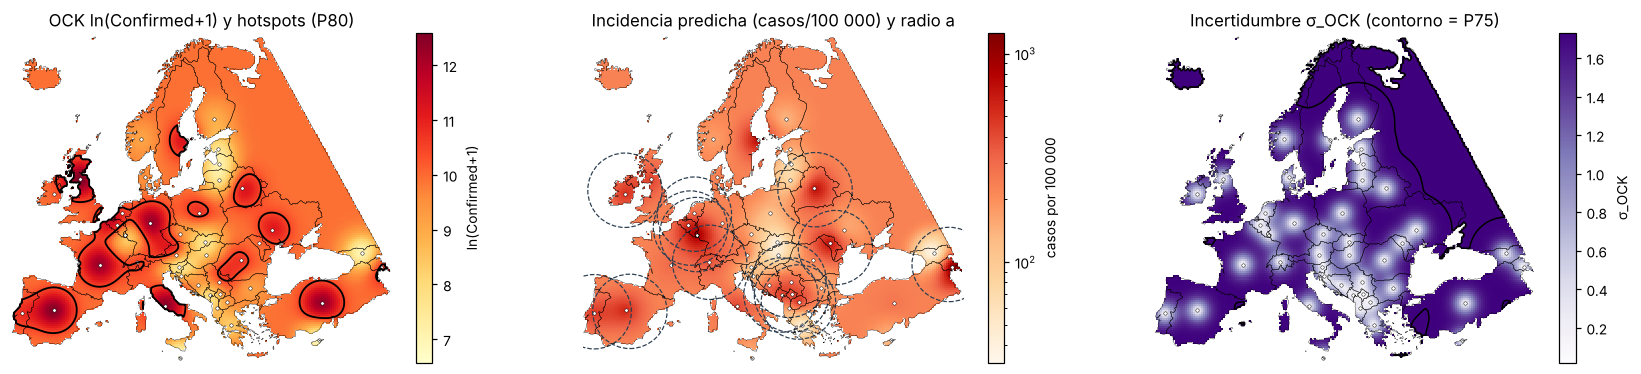

In [25]:
mediana_camas = resumen_pais["hospital_beds_per_thousand"].median()

# R1: hotspots (casos OCK o incidencia) con camas por debajo de la mediana europea
r1 = resumen_pais[((resumen_pais["pct_hotspot"] >= 50) | (resumen_pais["pct_hot_inc"] >= 50)) &
                  (resumen_pais["hospital_beds_per_thousand"] < mediana_camas)].copy()
r1["deficit_camas"] = (mediana_camas - r1["hospital_beds_per_thousand"]) * r1["population"] / 1000
# R2: incertidumbre; distancia al sitio más cercano a partir de la cual σ_OCK supera el umbral
d_vecino = cKDTree(xy).query(nodos)[0]
orden = np.argsort(d_vecino)
bins = np.arange(0, d_vecino.max() + 50, 50)
sd_por_dist = pd.Series(sd_ock).groupby(np.digitize(d_vecino, bins)).mean()
dist_critica = bins[sd_por_dist.index[sd_por_dist.values >= UMBRAL_SD].min() - 1]
pct_area_incierta = 100 * df_nodos["incierto"].mean()
r2 = resumen_pais.query("pct_incierto >= 25").sort_values("pct_incierto", ascending=False)
# R3: radio de coordinación = alcance práctico de la incidencia alrededor de los hotspots de riesgo
hot_inc = resumen_pais.loc[resumen_pais["pct_hot_inc"] >= 50, "ADMIN"].tolist()
rep = paises_km.set_index("ADMIN").geometry.representative_point()
d_hot = cdist(np.column_stack([rep.x, rep.y]), np.column_stack([rep.loc[hot_inc].x, rep.loc[hot_inc].y])).min(1)
vecinos_hot = sorted(set(rep.index[(d_hot <= A_INC) & (d_hot > 0)]) & set(resumen_pais["ADMIN"]))

print(f"Umbral hotspot de casos (P80 OCK): ln = {UMBRAL_HOT:.2f} ≈ {np.expm1(UMBRAL_HOT):,.0f} casos acumulados")
print(f"Umbral hotspot de riesgo (P80 incidencia): {np.exp(UMBRAL_INC_HOT):,.0f} casos por 100 000 hab.")
print(f"Mediana de camas por 1000 hab. (países del estudio): {mediana_camas:.2f}")
print("\nR1. Hotspots con camas < mediana y déficit respecto de la mediana:")
display(r1[["ADMIN", "pct_hotspot", "pct_hot_inc", "casos_x100k_obs", "hospital_beds_per_thousand",
            "aged_65_older", "deficit_camas"]].round(1))
print(f"Déficit total: {r1['deficit_camas'].sum():,.0f} camas")
print(f"\nR2. Umbral σ_OCK (P75) = {UMBRAL_SD:.3f}; {pct_area_incierta:.1f} % del territorio con alta incertidumbre.")
print(f"σ_OCK supera el umbral cuando el sitio de reporte más cercano está a más de ≈ {dist_critica:.0f} km.")
display(r2[["ADMIN", "area_km2", "pct_incierto", "sd_ock_medio"]].round(2))
print(f"\nR3. Alcance práctico de la incidencia a = {A_INC:.0f} km. Hotspots de riesgo: {hot_inc}")
print(f"Países a menos de {A_INC:.0f} km de un hotspot de riesgo (zona de coordinación): {vecinos_hot}")

recomendaciones = pd.DataFrame({
    "Recomendación": ["R1 Capacidad hospitalaria", "R2 Vigilancia", "R3 Coordinación territorial"],
    "Indicador": [f"{len(r1)} países hotspot con camas < {mediana_camas:.2f}/1000; déficit {r1['deficit_camas'].sum():,.0f} camas",
                  f"{pct_area_incierta:.1f} % del territorio con σ_OCK ≥ {UMBRAL_SD:.2f}; distancia crítica ≈ {dist_critica:.0f} km",
                  f"Radio de dependencia a = {A_INC:.0f} km; {len(vecinos_hot)} países en zona de coordinación"]})
display(recomendaciones)
recomendaciones.to_csv(RES / "f4_recomendaciones.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
mapa(axes[0], z1_ock, "OCK ln(Confirmed+1) y hotspots (P80)", "YlOrRd", "ln(Confirmed+1)")
Zg = a_grilla(z1_ock)
axes[0].contour(GX, GY, np.where(np.isnan(Zg), Zg[~np.isnan(Zg)].min(), Zg), levels=[UMBRAL_HOT], colors="k", linewidths=1.2)
mapa(axes[1], np.exp(inc_ok), "Incidencia predicha (casos/100 000) y radio a", "OrRd", "casos por 100 000",
     norm=LogNorm())
for x0, y0 in zip(rep.loc[hot_inc].x, rep.loc[hot_inc].y):
    axes[1].add_patch(plt.Circle((x0, y0), A_INC, fill=False, ls="--", color="#2c3e50", lw=0.8))
mapa(axes[2], sd_ock, "Incertidumbre σ_OCK (contorno = P75)", "Purples", "σ_OCK")
Sg = a_grilla(sd_ock)
axes[2].contour(GX, GY, np.where(np.isnan(Sg), 0, Sg), levels=[UMBRAL_SD], colors="k", linewidths=1)
for ax in axes:
    ax.set_xlim(EXTENT[:2]); ax.set_ylim(EXTENT[2:])
guardar_fig(fig, "f4_hotspots_incertidumbre")
plt.show()

### 4.1 Recomendaciones cuantitativas

**R1. Reforzar capacidad hospitalaria donde coinciden *hotspot* y déficit de camas.** Se definen como *hotspot* las zonas en el quintil superior de la superficie OCK (≥ ≈ 35 000 casos acumulados) o de la incidencia (≥ 280 casos por 100 000 hab.). Ocho países cumplen la condición de *hotspot* (≥ 50 % de su territorio) y tienen menos camas que la mediana europea (4,5 por 1000 hab.): **Reino Unido** (2,5 camas por 1000; déficit ≈ 132 700 camas), **España** (3,0; ≈ 73 000), **Países Bajos** (3,3; ≈ 20 800), **Portugal** (3,4; ≈ 11 500), **Irlanda** (3,0; ≈ 7 800), **Armenia**, **Macedonia del Norte** y **Montenegro**. El déficit total es de ≈ **247 400 camas** y el 83 % se concentra en Reino Unido y España, donde además más del 18 % de la población tiene 65 años o más. La redistribución de camas, personal y equipos de UCI debe priorizarse en ese orden.

**R2. Densificar la vigilancia donde la incertidumbre del Kriging es alta.** El 25 % del territorio tiene $\sigma_{OCK}\ge1{,}73$ (cuartil superior). Esa incertidumbre aparece cuando el sitio de reporte más cercano está a más de **≈ 450 km**, magnitud similar al alcance del semivariograma. Las zonas críticas son **Rusia europea** (74 % de su área con alta incertidumbre), **Noruega** (39 %), **Suecia** (33 %) y **Finlandia** (30 %). Se recomienda reportar a escala subnacional con al menos un punto de vigilancia cada ≈ 450 × 450 km (≈ 200 000 km²): unos **11 puntos en Rusia europea**, 3 en Suecia y 2 en Noruega y Finlandia. Así $\sigma_{OCK}$ bajaría del umbral en toda la región.

**R3. Coordinar restricciones en un radio igual al alcance espacial de la incidencia.** El semivariograma de la incidencia (pepita 0 %) tiene un alcance práctico de **≈ 461 km**: a esa distancia la incidencia de un país todavía informa sobre la de sus vecinos. Alrededor de los 14 *hotspots* de riesgo (España, Portugal, Países Bajos, Bélgica, Luxemburgo, Suiza, Irlanda, Bielorrusia, Moldavia, Armenia, Serbia, Kosovo, Macedonia del Norte y Montenegro), las medidas territoriales (controles fronterizos sanitarios, restricción de movilidad no esencial, intercambio de datos) deben acordarse en bloque con los **14 países** situados dentro de ese radio, entre ellos Francia, Alemania, Reino Unido, Rumania, Ucrania, Grecia y los Balcanes, en lugar de decidirse país por país.

## Conclusiones
1. **Proyección.** Las distancias en grados tienen un error mediano del 30 % (máximo 126 %) frente a la geodésica, y en EPSG:3035 el error es menor al 2,1 %. Proyectar es condición necesaria para un semivariograma válido.
2. **Corte temporal y transformación.** El corte al 26/07/2020 define una sola realización del campo aleatorio. La transformación $\ln(x+1)$ reduce la asimetría de 2,2 a −0,4 y restituye la normalidad (Shapiro-Wilk $p>0{,}3$).
3. **Soporte.** Homogeneizar el soporte (población ≥ 500 000) reduce la pepita relativa de 62 % a 23 % (WLS) y a ≈ 0 % (MV). Es la decisión con mayor efecto sobre la calidad del modelo.
4. **Patrón de puntos.** Los sitios no siguen CSR: son regulares a escala corta (inhibición política) y agregados a escala grande (vacíos al este). Por eso son un diseño fijo y el análisis recae en el atributo.
5. **Dependencia espacial.** La dependencia de los casos es fuerte: Gaussiano (MV), pepita ≈ 0, alcance ≈ 390 km. El OK supera a IDW y está bien calibrado (RMSS ≈ 1,02).
6. **Cokriging.** Con muestreo isotópico y corregionalización intrínseca, el OCK coincide con el OK. Con la secundaria co-localizada reduce el RMSE en 66 %, pero requiere recalibrar su varianza.

**Limitaciones.** (i) Cada dato es un centroide nacional, así que la superficie interpola agregados y no casos individuales (falacia ecológica, MAUP). (ii) Hay diferencias de testeo y de definición de caso entre países, que se suman a la pepita. (iii) Con $n=42$ los semivariogramas empíricos tienen pocos pares en los primeros *lags*. (iv) Rusia, cuyo centroide cae fuera de la ventana, no aporta datos, de ahí la alta incertidumbre al este. (v) El análisis es transversal: una extensión natural es el Kriging espacio-temporal con la serie completa.

In [26]:
# Exportación para la web (GitHub Pages): puntos con valores observados y validación cruzada
puntos_out = gdf.to_crs(CRS_GEO)[["Ubicacion", "Country/Region", "Lat", "Long", "Confirmed", "Deaths",
                                  "Recovered", "geometry"]].copy()
puntos_out["ln_confirmed"] = z1
puntos_out["ln_deaths"] = z2
puntos_out["loo_ok"] = cv["OK"][0]
puntos_out["loo_ock"] = cv["OCK isotópico"][0]
puntos_out.to_file(RES / "puntos_europa.geojson", driver="GeoJSON")
np.savez_compressed(RES / "superficies_grilla.npz", gx=gx, gy=gy, mask=MASK, idw=z1_idw, ok_conf=z1_ok,
                    ok_conf_var=z1_ok_var, ock_conf=z1_ock, ock_conf_var=z1_ock_var, ok_deaths=z2_ok,
                    ok_deaths_var=z2_ok_var)
print("Figuras:", sorted(p.name for p in FIG.glob("*.png")))
print("Resultados:", sorted(p.name for p in RES.iterdir()))

Figuras: ['f1_distancias_grados_vs_proyectadas.png', 'f1_mapa_puntos.png', 'f1_serie_temporal_europa.png', 'f1_transformacion_log.png', 'f2_csr_G_F_J_L.png', 'f2_idw_potencias.png', 'f2_kde_anchos_banda.png', 'f2_lisa_getis.png', 'f3_lmc_variogramas.png', 'f3_ok_deaths.png', 'f3_ok_vs_ock_confirmed.png', 'f3_semivariograma_confirmed.png', 'f3_validacion_cruzada.png', 'f4_hotspots_incertidumbre.png']
Resultados: ['f0_auditoria_calidad.csv', 'f0_impacto.csv', 'f1_comparacion_soporte.csv', 'f1_error_distancias.csv', 'f1_flujo_registros.csv', 'f1_forma_distribucion.csv', 'f2_csr.csv', 'f2_idw_validacion_cruzada.csv', 'f2_kde_anchos.csv', 'f2_lisa_getis.csv', 'f2_moran.csv', 'f3_lmc.csv', 'f3_ok_vs_uk_deaths.csv', 'f3_validacion_cruzada.csv', 'f3_variograma_confirmed_modelos.csv', 'f3_variograma_deaths_modelos.csv', 'f4_recomendaciones.csv', 'f4_resumen_por_pais.csv', 'f4_variograma_incidencia.csv', 'puntos_europa.geojson', 'superficies_grilla.npz']


In [ ]:
# Exportación para la web
import json
import shutil
from pathlib import Path
from pyproj import Transformer
from rasterio.transform import from_bounds
from rasterio.warp import calculate_default_transform, reproject, Resampling
from PIL import Image
from skimage.measure import find_contours
from shapely.geometry import LineString, mapping

web_out = globals().get('WEB_EXPORT_ROOT', BASE / 'web' / 'public' / 'data')
web_out = Path(web_out)
web_out.mkdir(parents=True, exist_ok=True)
(web_out / 'rasters').mkdir(exist_ok=True)
official_res = Path(globals().get('WEB_EXPORT_SOURCE_RES', RES))

def web_clean(value):
    if isinstance(value, dict):
        return {str(k): web_clean(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [web_clean(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    return value

def web_json(name, value):
    (web_out / name).write_text(json.dumps(web_clean(value), ensure_ascii=False, separators=(',', ':'), allow_nan=False), encoding='utf-8')

def records(frame):
    return frame.replace({np.nan: None}).to_dict(orient='records')

# Las tablas oficiales se conservan sin recalcular ni modificar sus fuentes.
for path in official_res.glob('*.csv'):
    shutil.copyfile(path, web_out / path.name)
    web_json(path.stem + '.json', records(pd.read_csv(path)))

official_dist = pd.read_csv(official_res / 'f1_error_distancias.csv')
official_cv = pd.read_csv(official_res / 'f3_validacion_cruzada.csv')
official_var = pd.read_csv(official_res / 'f3_variograma_confirmed_modelos.csv')
official_recommendations = pd.read_csv(official_res / 'f4_recomendaciones.csv')
selected_var = official_var[(official_var['Método'] == METODO) & (official_var['Modelo'] == MODELO)].iloc[0]
official_ok = official_cv[official_cv['Estimador'] == 'OK'].iloc[0]
official_coloc = official_cv[official_cv['Estimador'] == 'OCK co-localizado'].iloc[0]
web_json('kpis.json', {
    'distance_error_original': official_dist.iloc[0]['Error relativo mediano (%)'],
    'distance_error_projected': official_dist.iloc[1]['|Error| máximo (%)'],
    'locations_all': len(xy_all), 'locations_modeled': len(xy),
    'spatial_range_km': selected_var['Alcance a (km)'], 'ok_rmse': official_ok['RMSE'],
    'ok_rmss': official_ok['RMSS'],
    'cokriging_reduction_percent': 100 * (1 - official_coloc['RMSE'] / official_ok['RMSE']),
    'hospital_bed_deficit': r1['deficit_camas'].sum()
})

web_json('f1_pares_distancias.json', [dict(d_geo=a, d_deg=b, d_proj=c, lat_media=d) for a,b,c,d in zip(d_geo_km, d_grados_km, d_proj_km, (lat[i]+lat[j])/2)])
web_json('f1_serie_europa.json', records(serie.reset_index().assign(Date=lambda d: d.Date.astype(str))))
web_json('f1_distribucion.json', [dict(original=a, transformed=b) for a,b in zip(Z1_all, np.log1p(Z1_all))])

# Intervalos y frecuencias del histograma, calculados durante la exportación.
histograms = {}
for label, values, bins in [('original', Z1_all, 25), ('transformed', np.log1p(Z1_all), 15)]:
    counts, edges = np.histogram(values, bins=bins)
    histograms[label] = [dict(lower=edges[k], upper=edges[k+1], count=counts[k]) for k in range(len(counts))]
web_json('f1_histograma.json', histograms)

all_points = corte[(corte['WHO Region'] == 'Europe') & corte['Long'].between(BBOX[0], BBOX[2]) & corte['Lat'].between(BBOX[1], BBOX[3])].copy()
all_points['Ubicacion'] = all_points['Province/State'].fillna(all_points['Country/Region'])
all_points['soporte_ok'] = all_points['Ubicacion'].isin(eu['Ubicacion'])
all_geo = gpd.GeoDataFrame(all_points[['Ubicacion','Confirmed','Deaths','Recovered','soporte_ok']], geometry=gpd.points_from_xy(all_points['Long'], all_points['Lat']), crs=CRS_GEO)
web_json('puntos_todos.geojson', json.loads(all_geo.to_json(drop_id=True)))
model_geo = gpd.GeoDataFrame(eu[['Ubicacion','Confirmed','Deaths','LISA','Gi*_z','Gi*_p']].copy(), geometry=gpd.points_from_xy(eu['Long'], eu['Lat']), crs=CRS_GEO)
for name, values in cv.items():
    model_geo['loo_' + {'OK':'ok', 'OCK isotópico':'ock', 'OCK co-localizado':'coloc'}[name]] = values[0]
web_json('puntos_europa.geojson', json.loads(model_geo.to_json(drop_id=True)))

curves = {}
for label, observed, simulated in [('G',G_obs,G_sim), ('F',F_obs,F_sim), ('J',J_obs,J_sim), ('L',L_obs,L_sim)]:
    curves[label] = [dict(radius=r, observed=o, minimum=np.nanmin(s), maximum=np.nanmax(s), mean=np.nanmean(s)) for r,o,s in zip(radios, observed, simulated.T) if label != 'J' or r <= 550]
web_json('f2_csr_curvas.json', curves)
distances = np.linspace(0, MAXLAG, 200)
web_json('f3_variograma.json', {'empirical':[dict(h=h,g=g,n=n) for h,g,n in zip(h1,g1,n1)], 'curves':[{'method':row['Método'], 'model':row['Modelo'], 'points':[dict(h=h,g=g) for h,g in zip(distances, gamma_modelo(distances,row['Nugget c0'],row['Meseta parcial c'],row['Alcance a (km)'],row['Modelo']))]} for _,row in ajustes_z1.iterrows()]})
web_json('f3_lmc.json', [{'component':label, 'empirical':[dict(h=h,g=g,n=n) for h,g,n in zip(*empiricos[pair])], 'curve':[dict(h=h,g=g) for h,g in zip(distances,gamma_lmc(*pair,distances))]} for label,pair in [('11',(0,0)),('12',(0,1)),('22',(1,1))]])
idw_cv = loo_idw(p_opt)
web_json('f3_cv_puntos.json', [dict(location=eu.iloc[k]['Ubicacion'], observed=z1[k], idw=idw_cv[k], ok=cv['OK'][0][k], ock=cv['OCK isotópico'][0][k], coloc=cv['OCK co-localizado'][0][k]) for k in range(len(z1))])
web_json('f4_recomendaciones.json', {'r1':{'countries':records(r1), 'total_deficit':r1['deficit_camas'].sum(), 'median_beds':mediana_camas}, 'r2':{'countries':records(r2), 'uncertainty_threshold':UMBRAL_SD, 'area_percent':pct_area_incierta, 'critical_distance_km':dist_critica}, 'r3':{'hotspots':hot_inc, 'neighbors':vecinos_hot, 'range_km':A_INC}})
country_geo = paises_p[['ADMIN','geometry']].copy()
country_geo.geometry = country_geo.geometry.simplify(2000, preserve_topology=True)
country_geo = country_geo.to_crs(CRS_GEO).merge(resumen_pais, on='ADMIN', how='left')
web_json('paises_resumen.geojson', json.loads(country_geo.to_json(drop_id=True, na='null')))

to_geo = Transformer.from_crs(CRS_PROJ, CRS_GEO, always_xy=True)
features = []
for label, values, threshold in [('ock_p80',z1_ock,UMBRAL_HOT), ('sd_p75',sd_ock,UMBRAL_SD)]:
    grid = a_grilla(values)
    for line in find_contours(np.nan_to_num(grid, nan=float(np.nanmin(grid))-1), threshold):
        xx = np.interp(line[:,1], np.arange(len(gx)), gx) * 1000
        yy = np.interp(line[:,0], np.arange(len(gy)), gy) * 1000
        lon_line,lat_line = to_geo.transform(xx,yy)
        if len(lon_line) >= 2:
            features.append({'type':'Feature','properties':{'id':label,'threshold':threshold},'geometry':mapping(LineString(zip(lon_line,lat_line)))})
# Radios de dependencia de incidencia alrededor de cada país de alto riesgo.
for country in hot_inc:
    ring = rep.loc[country].buffer(A_INC, quad_segs=24).exterior
    x_ring, y_ring = ring.xy
    lon_ring, lat_ring = to_geo.transform(np.asarray(x_ring) * 1000, np.asarray(y_ring) * 1000)
    features.append({'type':'Feature', 'properties':{'id':'incidence_radius', 'country':country, 'radius_km':A_INC}, 'geometry':mapping(LineString(zip(lon_ring, lat_ring)))})
web_json('contornos.geojson', {'type':'FeatureCollection','features':features})

# Las superficies se reproyectan de la grilla métrica al plano del mapa.
surfaces = {}
for power in [1,1.5,2,4,6]:
    surfaces['idw_p'+str(power).replace('.','_')] = (idw(xy,z1,nodos,power), 'YlOrRd', 'ln(Confirmed+1)')
for suffix,bandwidth in [('h05',h_opt/2),('h1',h_opt),('h2',h_opt*2)]:
    surfaces['kde_sitios_'+suffix] = (kde_gauss(xy_all,np.ones(len(xy_all)),bandwidth,nodos)*1e4, 'YlOrRd', 'sitios / 10 000 km²')
    surfaces['kde_casos_'+suffix] = (kde_gauss(xy_all,Z1_all.astype(float),bandwidth,nodos)*1e2, 'YlOrRd', 'casos / 100 km²')
surfaces.update({'ok_conf':(z1_ok,'YlOrRd','ln(Confirmed+1)'), 'ock_conf':(z1_ock,'YlOrRd','ln(Confirmed+1)'), 'ok_conf_sd':(np.sqrt(z1_ok_var),'Purples','σ'), 'ock_conf_sd':(sd_ock,'Purples','σ'), 'ok_deaths':(z2_ok,'Reds','ln(Deaths+1)'), 'ok_deaths_sd':(np.sqrt(z2_ok_var),'Purples','σ'), 'inc_ok':(np.exp(inc_ok),'YlOrRd','casos / 100 000')})
shared_pred = [float(min(np.min(z1_ok),np.min(z1_ock))),float(max(np.max(z1_ok),np.max(z1_ock)))]
shared_sd = [0.,float(max(np.max(np.sqrt(z1_ok_var)),np.max(sd_ock)))]
src_transform = from_bounds(EXTENT[0]*1000,EXTENT[2]*1000,EXTENT[1]*1000,EXTENT[3]*1000,len(gx),len(gy))
dst_transform, width, height = calculate_default_transform(CRS_PROJ,'EPSG:3857',len(gx),len(gy),EXTENT[0]*1000,EXTENT[2]*1000,EXTENT[1]*1000,EXTENT[3]*1000)
width = min(width, 1600)
to_lonlat = Transformer.from_crs('EPSG:3857',CRS_GEO,always_xy=True)
left,top = dst_transform*(0,0)
right,bottom = dst_transform*(width,height)
corners = [list(to_lonlat.transform(x,y)) for x,y in [(left,top),(right,top),(right,bottom),(left,bottom)]]
rasters = []
for name,(values,palette,unit) in surfaces.items():
    source = np.flipud(a_grilla(values)).astype('float32')
    destination = np.full((height,width),np.nan,dtype='float32')
    reproject(source,destination,src_transform=src_transform,src_crs=CRS_PROJ,src_nodata=np.nan,dst_transform=dst_transform,dst_crs='EPSG:3857',dst_nodata=np.nan,resampling=Resampling.bilinear)
    domain = shared_pred if name in ('ok_conf','ock_conf') else shared_sd if name in ('ok_conf_sd','ock_conf_sd') else [float(np.nanmin(destination)),float(np.nanmax(destination))]
    normalized = np.clip((destination-domain[0])/(domain[1]-domain[0] or 1),0,1)
    rgba = (plt.get_cmap(palette)(np.nan_to_num(normalized,nan=0))*255).astype('uint8')
    rgba[:,:,3] = np.where(np.isfinite(destination),255,0).astype('uint8')
    Image.fromarray(rgba,'RGBA').save(web_out/'rasters'/f'{name}.png',optimize=True)
    rasters.append({'id':name,'file':f'rasters/{name}.png','coordinates':corners,'domain':domain,'palette':palette,'unit':unit,'label':name})
web_json('rasters.json',rasters)
grid_sample = np.arange(0,len(nodos),2)
glon,glat = to_geo.transform(nodos[grid_sample,0]*1000,nodos[grid_sample,1]*1000)
web_json('valores_grilla.json',[{'lon':a,'lat':b,'ock_conf':c,'sd':d,'incidence':e} for a,b,c,d,e in zip(glon,glat,z1_ock[grid_sample],sd_ock[grid_sample],inc_ok[grid_sample])])
print(f'Exportación completada en {web_out}')
